In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rdkit import Chem
from rdkit.Chem import rdChemReactions
from rdkit.Chem import Draw
from rdkit.Chem import AllChem, rdchem

import re
import importlib
import numpy as np
from IPython.display import display, Markdown
import ipywidgets as widgets
import importlib.util, sys, types
import ipywidgets as widgets
from IPython.display import display

In [3]:
# Extract atomic symbol
def extract_symbol(s):
    if s.startswith("#"):
        try:
            num = int(re.findall(r"#(\d+)", s)[0])
            return Chem.GetPeriodicTable().GetElementSymbol(num)
        except:
            return "*"
    match = re.match(r"([A-Z][a-z]?)", s)
    return match.group(1) if match else "*"

# Label atoms
def set_query_atom_labels(mol, mode='clean'):
    for atom in mol.GetAtoms():
        if not atom.HasQuery():
            continue

        smarts = Chem.MolFragmentToSmarts(mol, atomsToUse=[atom.GetIdx()])
        if not (smarts.startswith("[") and smarts.endswith("]")):
            atom.SetProp("_displayLabel", atom.GetSymbol())
            continue

        inner = smarts[1:-1]

        if mode == 'query':
            atom.SetProp("_displayLabel", inner)
            continue

        # clean mode
        parts = re.split(r"[;&]", inner)
        symbol_raw = parts[0]
        if ":" in symbol_raw:
            symbol_raw = symbol_raw.split(":")[0]
        symbol = extract_symbol(symbol_raw)

        hcount = None
        charge = None
        for part in parts[1:]:
            if part.startswith("H"):
                try:
                    hcount = int(part[1:])
                except:
                    pass
            elif part.startswith("+") or part.startswith("-"):
                match = re.match(r"[+-]\d*", part)
                if match:
                    charge = match.group()

        label = symbol
        if hcount == 1:
            label += "H"
        elif hcount and hcount > 1:
            label += f"H{hcount}"
        if charge not in (None, "+0", "-0", "0"):
            label += charge

        atom.SetProp("_displayLabel", label)

# Draw reaction
def draw_reaction_smarts(smarts, mode='clean'):
    try:
        rxn = rdChemReactions.ReactionFromSmarts(smarts, useSmiles=False)
        for mol in rxn.GetReactants():
            set_query_atom_labels(mol, mode)
        for mol in rxn.GetProducts():
            set_query_atom_labels(mol, mode)
        return Draw.ReactionToImage(rxn, subImgSize=(300, 200))
    except Exception as e:
        return f"Error: {e}"

In [4]:
import groups
importlib.reload(groups)
import elem_steps
steps = elem_steps.steps
importlib.reload(elem_steps)
import reaction_templates
importlib.reload(reaction_templates)

<module 'reaction_templates' from '/home/erick/ColeyLinux/Mechanistic_dataset/new_templates/reaction_templates.py'>

In [5]:
class_reaction_templates = reaction_templates.class_reaction_templates

# Count how many reaction classes are available:
all_classes = []
for class_key in class_reaction_templates:
    # class_key might be a tuple of class names or a single string
    if isinstance(class_key, tuple):
        all_classes.extend(list(class_key))
    else:
        all_classes.append(class_key)
all_classes_count = len(all_classes)
print(f"Loaded reaction templates for {all_classes_count} reaction classes.")

Loaded reaction templates for 64 reaction classes.


In [6]:
reaction_dict = class_reaction_templates 

class_dropdown = widgets.Dropdown(options=list(reaction_dict.keys()), description='Class:')
mech_dropdown = widgets.Dropdown(description='Mechanism:')
step_dropdown = widgets.Dropdown(description='Step:')
mode_dropdown = widgets.Dropdown(options=['clean', 'query'], value='clean', description='Mode:')
output = widgets.Output()

# Update mechanism list
def update_mechanisms(change):
    mech_dict = reaction_dict[change['new']]
    mech_dropdown.options = list(mech_dict.keys())
    if mech_dropdown.options:
        mech_dropdown.value = mech_dropdown.options[0]
        update_steps({'new': mech_dropdown.value})


# Update step list
def update_steps(change):
    mech_data = reaction_dict[class_dropdown.value][change['new']]
#     print("Selected class:", class_dropdown.value)
#     print("Selected reaction:", change['new'])
#     print("Stages available:", list(mech_data.get("Stages", {}).keys()))
    step_dropdown.options = list(mech_data.get("Stages", {}).keys())
    if step_dropdown.options:
        step_dropdown.value = step_dropdown.options[0]

# Display selected step
def display_step(change=None):
    with output:
        output.clear_output()
        cls = class_dropdown.value
        mech = mech_dropdown.value
        step = step_dropdown.value
        mode = mode_dropdown.value
        data = reaction_dict[cls][mech]
        reagent = data.get("Reagent", "N/A")
        exclude = data.get("Exclude_reagent", "N/A")
        stage_data = data["Stages"].get(step, {})

        if isinstance(stage_data, dict) and "Templates" in stage_data:
            templates = stage_data["Templates"]
            description = stage_data.get("Description", "")
        else:
            templates = [stage_data] if isinstance(stage_data, str) else []
            description = ""

        print(f"[{cls} - {mech}]")
        print(f"Reagent: {reagent}")
        print(f"Exclude: {exclude}")
        print(f"Step: {step}")
        if description:
            print(f"Description: {description}")
        for i, tpl in enumerate(templates):
            print(f"Template {i+1}: {tpl}")
            img = draw_reaction_smarts(tpl, mode)
            if isinstance(img, str):
                print(img)
            else:
                display(img)

# Bind events
class_dropdown.observe(update_mechanisms, names='value')
mech_dropdown.observe(update_steps, names='value')
step_dropdown.observe(display_step, names='value')
mode_dropdown.observe(display_step, names='value')

# Trigger initial updates
update_mechanisms({'new': class_dropdown.value})
update_steps({'new': mech_dropdown.value})
display_step()

# Show UI
ui = widgets.VBox([
    class_dropdown,
    mech_dropdown,
    step_dropdown,
    mode_dropdown,
    output
])
display(ui)


In [7]:
def remove_atom_mapping(smarts):
    import re
    smarts = re.sub(r"\:\d+\]", "]", smarts)
    return re.sub(r"\[\d+", "[", smarts)

In [8]:
smi1 = "Br[c:6]1[cH:5][n:4][c:3]([O:2][CH3:1])[cH:8][cH:7]1.[CH2:9]=[CH:10][C:11]#[N:12].CCN(CC)CC.CN(C)C=O.c1ccc([P](c2ccccc2)c2ccccc2)cc1.c1ccc([P](c2ccccc2)c2ccccc2)cc1.Cl[Pd]Cl>>[CH3:1][O:2][c:3]1[cH:8][cH:7][c:6]([cH:5][n:4]1)[CH:9]=[CH:10][C:11]#[N:12].[CH3:1][O:2][c:3]1[cH:8][cH:7][c:6]([cH:5][n:4]1)[CH:9]=[CH:10][C:11]#[N:12]"

In [9]:
smi1 = "[B:1]([c:2]1[c:3]([H:76])[n:4]([H:77])[n:5][c:6]1[H:78])([O:7][H:79])[O:8][H:80].[C:19]([C:20]([C:21]([C:22]([P:23]([C@@:24]12[C:25]([H:94])([H:95])[C@@:26]3([H:96])[C:27]([H:97])([H:98])[C@@:28]([H:99])([C:29]1([H:100])[H:101])[C:30]([H:102])([H:103])[C@:31]([H:104])([C:32]3([H:105])[H:106])[C:33]2([H:107])[H:108])([C@@:34]12[C:35]([H:109])([H:110])[C@@:36]3([H:111])[C:37]([H:112])([H:113])[C@@:38]([H:114])([C:39]1([H:115])[H:116])[C:40]([H:117])([H:118])[C@:41]([H:119])([C:42]3([H:120])[H:121])[C:43]2([H:122])[H:123])[Pd:44]1([O:58][S:59](=[O:60])(=[O:61])[C:62]([H:134])([H:135])[H:136])[c:45]2[c:46]([H:124])[c:47]([H:125])[c:48]([H:126])[c:49]([H:127])[c:50]2-[c:51]2[c:52]([H:128])[c:53]([H:129])[c:54]([H:130])[c:55]([H:131])[c:56]2[N:57]1([H:132])[H:133])([H:92])[H:93])([H:90])[H:91])([H:88])[H:89])([H:85])([H:86])[H:87].[C:63]1([H:137])([H:138])[C:64]([H:139])([H:140])[O:65][C:66]([H:141])([H:142])[C:67]([H:143])([H:144])[O:68]1.[C:69](=[O:70])([O:71][K:72])[O:73][K:74].[O:147]=[C:148]([O:149][K:150])[O:151][K:152].[O:75]([H:145])[H:146].[c:9]1([H:81])[c:10]([Cl:18])[c:11]([Br:17])[c:12]([H:82])[c:13]([F:16])[c:14]1[N:15]([H:83])[H:84]>>[B:1]([c:2]1[c:3]([H:76])[n:4]([H:77])[n:5][c:6]1[H:78])([O:7][H:79])[O:8][H:80].[C:19]([C:20]([C:21]([C:22]([P:23]([C@@:24]12[C:25]([H:94])([H:95])[C@@:26]3([H:96])[C:27]([H:97])([H:98])[C@@:28]([H:99])([C:29]1([H:100])[H:101])[C:30]([H:102])([H:103])[C@:31]([H:104])([C:32]3([H:105])[H:106])[C:33]2([H:107])[H:108])([C@@:34]12[C:35]([H:109])([H:110])[C@@:36]3([H:111])[C:37]([H:112])([H:113])[C@@:38]([H:114])([C:39]1([H:115])[H:116])[C:40]([H:117])([H:118])[C@:41]([H:119])([C:42]3([H:120])[H:121])[C:43]2([H:122])[H:123])[Pd:44]1[c:45]2[c:46]([H:124])[c:47]([H:125])[c:48]([H:126])[c:49]([H:127])[c:50]2-[c:51]2[c:52]([H:128])[c:53]([H:129])[c:54]([H:130])[c:55]([H:131])[c:56]2[N:57]1[H:132])([H:92])[H:93])([H:90])[H:91])([H:88])[H:89])([H:85])([H:86])[H:87].[C:63]1([H:137])([H:138])[C:64]([H:139])([H:140])[O:65][C:66]([H:141])([H:142])[C:67]([H:143])([H:144])[O:68]1.[C:69](=[O:70])([O:71][H:133])[O:73][K:74].[K+:72].[O-:58][S:59](=[O:60])(=[O:61])[C:62]([H:134])([H:135])[H:136].[O:147]=[C:148]([O:149][K:150])[O:151][K:152].[O:75]([H:145])[H:146].[c:9]1([H:81])[c:10]([Cl:18])[c:11]([Br:17])[c:12]([H:82])[c:13]([F:16])[c:14]1[N:15]([H:83])[H:84]"

smi1 = Chem.MolToSmiles(Chem.MolFromSmiles(smi1, ps), isomericSmiles=False, canonical=True, allHsExplicit=True)
print(smi1)

NameError: name 'ps' is not defined

In [ ]:
smi1 = "[B-:1]([c:2]1[c:3]([N+:8](=[O:9])[O-:10])[c:4]([H:128])[c:5]([H:129])[c:6]([H:130])[c:7]1[H:131])([O:11][H:132])([O:12][H:133])[O:37][C:36]([C:35]([H:145])([H:146])[H:147])([H:148])[H:149].[B:23]([c:24]1[c:25]([N+:30](=[O:31])[O-:32])[c:26]([H:139])[c:27]([H:140])[c:28]([H:141])[c:29]1[H:142])([O:33][H:143])[O:34][H:144].[C:122](=[O:123])([O:124][H:150])[O:126][K:127].[C:38]([c:39]1[c:40]([H:154])[c:41]([H:155])[c:42]([H:156])[c:43]([H:157])[c:44]1[H:158])([H:151])([H:152])[H:153].[K+:125].[P:65]([c:66]1[c:67]([H:174])[c:68]([H:175])[c:69]([H:176])[c:70]([H:177])[c:71]1[H:178])([c:72]1[c:73]([H:179])[c:74]([H:180])[c:75]([H:181])[c:76]([H:182])[c:77]1[H:183])[c:78]1[c:79]([H:184])[c:80]([H:185])[c:81]([H:186])[c:82]([H:187])[c:83]1[H:188].[P:84]([c:85]1[c:86]([H:189])[c:87]([H:190])[c:88]([H:191])[c:89]([H:192])[c:90]1[H:193])([c:91]1[c:92]([H:194])[c:93]([H:195])[c:94]([H:196])[c:95]([H:197])[c:96]1[H:198])[c:97]1[c:98]([H:199])[c:99]([H:200])[c:100]([H:201])[c:101]([H:202])[c:102]1[H:203].[c:13]1([H:134])[c:14]([H:135])[c:15]([H:136])[c:16]2[c:17]([c:18]1[H:137])[c:19]([Pd:64]([Br:22])[P:103]([c:104]1[c:105]([H:204])[c:106]([H:205])[c:107]([H:206])[c:108]([H:207])[c:109]1[H:208])([c:110]1[c:111]([H:209])[c:112]([H:210])[c:113]([H:211])[c:114]([H:212])[c:115]1[H:213])[c:116]1[c:117]([H:214])[c:118]([H:215])[c:119]([H:216])[c:120]([H:217])[c:121]1[H:218])[c:20]([H:138])[s:21]2.[c:45]1([H:159])[c:46]([H:160])[c:47]([H:161])[c:48]([P:51]([c:52]2[c:53]([H:164])[c:54]([H:165])[c:55]([H:166])[c:56]([H:167])[c:57]2[H:168])[c:58]2[c:59]([H:169])[c:60]([H:170])[c:61]([H:171])[c:62]([H:172])[c:63]2[H:173])[c:49]([H:162])[c:50]1[H:163]>>[B-:1]([c:2]1[c:3]([N+:8](=[O:9])[O-:10])[c:4]([H:128])[c:5]([H:129])[c:6]([H:130])[c:7]1[H:131])([O+:11](->[Pd:64]([c:19]1[c:17]2[c:16]([c:15]([H:136])[c:14]([H:135])[c:13]([H:134])[c:18]2[H:137])[s:21][c:20]1[H:138])[P:103]([c:104]1[c:105]([H:204])[c:106]([H:205])[c:107]([H:206])[c:108]([H:207])[c:109]1[H:208])([c:110]1[c:111]([H:209])[c:112]([H:210])[c:113]([H:211])[c:114]([H:212])[c:115]1[H:213])[c:116]1[c:117]([H:214])[c:118]([H:215])[c:119]([H:216])[c:120]([H:217])[c:121]1[H:218])[H:132])([O:12][H:133])[O:37][C:36]([C:35]([H:145])([H:146])[H:147])([H:148])[H:149].[B:23]([c:24]1[c:25]([N+:30](=[O:31])[O-:32])[c:26]([H:139])[c:27]([H:140])[c:28]([H:141])[c:29]1[H:142])([O:33][H:143])[O:34][H:144].[Br-:22].[C:122](=[O:123])([O:124][H:150])[O:126][K:127].[C:38]([c:39]1[c:40]([H:154])[c:41]([H:155])[c:42]([H:156])[c:43]([H:157])[c:44]1[H:158])([H:151])([H:152])[H:153].[K+:125].[P:65]([c:66]1[c:67]([H:174])[c:68]([H:175])[c:69]([H:176])[c:70]([H:177])[c:71]1[H:178])([c:72]1[c:73]([H:179])[c:74]([H:180])[c:75]([H:181])[c:76]([H:182])[c:77]1[H:183])[c:78]1[c:79]([H:184])[c:80]([H:185])[c:81]([H:186])[c:82]([H:187])[c:83]1[H:188].[P:84]([c:85]1[c:86]([H:189])[c:87]([H:190])[c:88]([H:191])[c:89]([H:192])[c:90]1[H:193])([c:91]1[c:92]([H:194])[c:93]([H:195])[c:94]([H:196])[c:95]([H:197])[c:96]1[H:198])[c:97]1[c:98]([H:199])[c:99]([H:200])[c:100]([H:201])[c:101]([H:202])[c:102]1[H:203].[c:45]1([H:159])[c:46]([H:160])[c:47]([H:161])[c:48]([P:51]([c:52]2[c:53]([H:164])[c:54]([H:165])[c:55]([H:166])[c:56]([H:167])[c:57]2[H:168])[c:58]2[c:59]([H:169])[c:60]([H:170])[c:61]([H:171])[c:62]([H:172])[c:63]2[H:173])[c:49]([H:162])[c:50]1[H:163]"
smi1 = "C>>[Br-].[H]OB(O[H])c1=c([N+](=O)[O-])-c([H])=c([H])-c([H])=c-1[H].[H]OC(=O)O[K].[H][O-][B-](OC([H])([H])C([H])([H])[H])(c1=c([N+](=O)[O-])-c([H])=c([H])-c([H])=c-1[H])[O+2]([H])[Pd](c1=c([H])-s-c2=c-1-c([H])=c([H])-c([H])=c-2[H])[P](c1=c([H])-c([H])=c([H])-c([H])=c-1[H])(c1=c([H])-c([H])=c([H])-c([H])=c-1[H])c1=c([H])-c([H])=c([H])-c([H])=c-1[H].[H]c1=c([H])-c([H])=c(C([H])([H])[H])-c([H])=c-1[H].[H]c1=c([H])-c([H])=c(P(c2=c([H])-c([H])=c([H])-c([H])=c-2[H])c2=c([H])-c([H])=c([H])-c([H])=c-2[H])-c([H])=c-1[H].[H]c1=c([H])-c([H])=c(P(c2=c([H])-c([H])=c([H])-c([H])=c-2[H])c2=c([H])-c([H])=c([H])-c([H])=c-2[H])-c([H])=c-1[H].[H]c1=c([H])-c([H])=c(P(c2=c([H])-c([H])=c([H])-c([H])=c-2[H])c2=c([H])-c([H])=c([H])-c([H])=c-2[H])-c([H])=c-1[H].[K+]"
smi1 = "[Br:66][c:67]1[c:68]([H:169])[n:69][c:70]([H:170])[c:71]2[c:72]1[s:73][c:74]([H:171])[n:75]2.[C:1]([C:2]([C:3]([H:95])([H:96])[H:97])([c:4]1[c:5]([H:98])[c:6]([C:7]([C:8]([H:100])([H:101])[H:102])([C:9]([H:103])([H:104])[H:105])[H:99])[c:10](-[c:11]2[c:12]([H:106])[c:13]([H:107])[c:14]([H:108])[c:15]([H:109])[c:16]2[P:17]([C:18]2([H:110])[C:19]([H:111])([H:112])[C:20]([H:113])([H:114])[C:21]([H:115])([H:116])[C:22]([H:117])([H:118])[C:23]2([H:119])[H:120])([C:24]2([H:121])[C:25]([H:122])([H:123])[C:26]([H:124])([H:125])[C:27]([H:126])([H:127])[C:28]([H:128])([H:129])[C:29]2([H:130])[H:131])[Pd:30]([Cl:31])[c:32]2[c:33]([H:132])[c:34]([H:133])[c:35]([H:134])[c:36]([H:135])[c:37]2-[c:38]2[c:39]([H:136])[c:40]([H:137])[c:41]([H:138])[c:42]([H:139])[c:43]2[N:44]([H:140])[H:141])[c:45]([C:46]([C:47]([H:143])([H:144])[H:145])([C:48]([H:146])([H:147])[H:148])[H:142])[c:49]1[H:149])[H:94])([H:91])([H:92])[H:93].[C:50]([C:51]1([C:52]([H:153])([H:154])[H:155])[O:53][B:54]([c:55]2[c:56]([C:57]([H:156])([H:157])[H:158])[n:58]([C:59]([H:159])([H:160])[H:161])[n:60][c:61]2[H:162])[O:62][C:63]1([C:64]([H:163])([H:164])[H:165])[C:65]([H:166])([H:167])[H:168])([H:150])([H:151])[H:152].[C:76]1([H:172])([H:173])[C:77]([H:174])([H:175])[O:78][C:79]([H:176])([H:177])[C:80]([H:178])([H:179])[O:81]1.[N:88]#[N:89].[O:182]=[C:183]([O:184][Na:185])[O:186][Na:187].[O:82]=[C:83]([O:84][Na:85])[O:86][Na:87].[O:90]([H:180])[H:181]>>[Br:66][c:67]1[c:68]([H:169])[n:69][c:70]([H:170])[c:71]2[c:72]1[s:73][c:74]([H:171])[n:75]2.[C:1]([C:2]([C:3]([H:95])([H:96])[H:97])([c:4]1[c:5]([H:98])[c:6]([C:7]([C:8]([H:100])([H:101])[H:102])([C:9]([H:103])([H:104])[H:105])[H:99])[c:10](-[c:11]2[c:12]([H:106])[c:13]([H:107])[c:14]([H:108])[c:15]([H:109])[c:16]2[P:17]([C:18]2([H:110])[C:19]([H:111])([H:112])[C:20]([H:113])([H:114])[C:21]([H:115])([H:116])[C:22]([H:117])([H:118])[C:23]2([H:119])[H:120])([C:24]2([H:121])[C:25]([H:122])([H:123])[C:26]([H:124])([H:125])[C:27]([H:126])([H:127])[C:28]([H:128])([H:129])[C:29]2([H:130])[H:131])[Pd:30]2[c:32]3[c:33]([H:132])[c:34]([H:133])[c:35]([H:134])[c:36]([H:135])[c:37]3-[c:38]3[c:39]([H:136])[c:40]([H:137])[c:41]([H:138])[c:42]([H:139])[c:43]3[N:44]2[H:140])[c:45]([C:46]([C:47]([H:143])([H:144])[H:145])([C:48]([H:146])([H:147])[H:148])[H:142])[c:49]1[H:149])[H:94])([H:91])([H:92])[H:93].[C:50]([C:51]1([C:52]([H:153])([H:154])[H:155])[O:53][B:54]([c:55]2[c:56]([C:57]([H:156])([H:157])[H:158])[n:58]([C:59]([H:159])([H:160])[H:161])[n:60][c:61]2[H:162])[O:62][C:63]1([C:64]([H:163])([H:164])[H:165])[C:65]([H:166])([H:167])[H:168])([H:150])([H:151])[H:152].[C:76]1([H:172])([H:173])[C:77]([H:174])([H:175])[O:78][C:79]([H:176])([H:177])[C:80]([H:178])([H:179])[O:81]1.[Cl-:31].[N:88]#[N:89].[Na+:85].[O:182]=[C:183]([O:184][Na:185])[O:186][Na:187].[O:82]=[C:83]([O:84][H:141])[O:86][Na:87].[O:90]([H:180])[H:181]"
smi1 = "[B-:1]1([c:10]2[c:11]([H:134])[c:12]([H:135])[c:13](-[c:16]3[n:17][c:18]([H:138])[c:19]([H:139])[o:20]3)[c:14]([H:136])[c:15]2[H:137])([O:120][H:209])[O:2][C:3]([C:8]([H:128])([H:129])[H:130])([C:9]([H:131])([H:132])[H:133])[C:4]([C:6]([H:122])([H:123])[H:124])([C:7]([H:125])([H:126])[H:127])[O:5]1.[C:112](=[O:113])([O:114][H:210])[O:116][Cs:117].[C:21]([O:22][c:23]1[c:24]([O:34][C:35]([H:146])([H:147])[H:148])[c:25]([H:143])[c:26]2[c:27]([c:28]1[H:144])[c:29]([Pd:121]([Br:33])([P:42]([c:39]1[c:38]([H:151])[c:37]([H:150])[c:36]([H:149])[c:41]([H:153])[c:40]1[H:152])([c:43]1[c:44]([H:154])[c:45]([H:155])[c:46]([H:156])[c:47]([H:157])[c:48]1[H:158])[c:49]1[c:50]([H:159])[c:51]([H:160])[c:52]([H:161])[c:53]([H:162])[c:54]1[H:163])[P:80]([c:77]1[c:76]([H:181])[c:75]([H:180])[c:74]([H:179])[c:79]([H:183])[c:78]1[H:182])([c:81]1[c:82]([H:184])[c:83]([H:185])[c:84]([H:186])[c:85]([H:187])[c:86]1[H:188])[c:87]1[c:88]([H:189])[c:89]([H:190])[c:90]([H:191])[c:91]([H:192])[c:92]1[H:193])[c:30]([H:145])[n:31][n:32]2)([H:140])([H:141])[H:142].[Cs+:115].[N:118]#[N:119].[c:55]1([H:164])[c:56]([H:165])[c:57]([H:166])[c:58]([P:61]([c:62]2[c:63]([H:169])[c:64]([H:170])[c:65]([H:171])[c:66]([H:172])[c:67]2[H:173])[c:68]2[c:69]([H:174])[c:70]([H:175])[c:71]([H:176])[c:72]([H:177])[c:73]2[H:178])[c:59]([H:167])[c:60]1[H:168].[c:93]1([H:194])[c:94]([H:195])[c:95]([H:196])[c:96]([P:99]([c:100]2[c:101]([H:199])[c:102]([H:200])[c:103]([H:201])[c:104]([H:202])[c:105]2[H:203])[c:106]2[c:107]([H:204])[c:108]([H:205])[c:109]([H:206])[c:110]([H:207])[c:111]2[H:208])[c:97]([H:197])[c:98]1[H:198]>>[B-:1]1([c:10]2[c:11]([H:134])[c:12]([H:135])[c:13](-[c:16]3[n:17][c:18]([H:138])[c:19]([H:139])[o:20]3)[c:14]([H:136])[c:15]2[H:137])([O+:120](->[Pd:121]([c:29]2[c:27]3[c:26]([c:25]([H:143])[c:24]([O:34][C:35]([H:146])([H:147])[H:148])[c:23]([O:22][C:21]([H:140])([H:141])[H:142])[c:28]3[H:144])[n:32][n:31][c:30]2[H:145])([P:42]([c:39]2[c:38]([H:151])[c:37]([H:150])[c:36]([H:149])[c:41]([H:153])[c:40]2[H:152])([c:43]2[c:44]([H:154])[c:45]([H:155])[c:46]([H:156])[c:47]([H:157])[c:48]2[H:158])[c:49]2[c:50]([H:159])[c:51]([H:160])[c:52]([H:161])[c:53]([H:162])[c:54]2[H:163])[P:80]([c:77]2[c:76]([H:181])[c:75]([H:180])[c:74]([H:179])[c:79]([H:183])[c:78]2[H:182])([c:81]2[c:82]([H:184])[c:83]([H:185])[c:84]([H:186])[c:85]([H:187])[c:86]2[H:188])[c:87]2[c:88]([H:189])[c:89]([H:190])[c:90]([H:191])[c:91]([H:192])[c:92]2[H:193])[H:209])[O:2][C:3]([C:8]([H:128])([H:129])[H:130])([C:9]([H:131])([H:132])[H:133])[C:4]([C:6]([H:122])([H:123])[H:124])([C:7]([H:125])([H:126])[H:127])[O:5]1.[Br-:33].[C:112](=[O:113])([O:114][H:210])[O:116][Cs:117].[Cs+:115].[N:118]#[N:119].[c:55]1([H:164])[c:56]([H:165])[c:57]([H:166])[c:58]([P:61]([c:62]2[c:63]([H:169])[c:64]([H:170])[c:65]([H:171])[c:66]([H:172])[c:67]2[H:173])[c:68]2[c:69]([H:174])[c:70]([H:175])[c:71]([H:176])[c:72]([H:177])[c:73]2[H:178])[c:59]([H:167])[c:60]1[H:168].[c:93]1([H:194])[c:94]([H:195])[c:95]([H:196])[c:96]([P:99]([c:100]2[c:101]([H:199])[c:102]([H:200])[c:103]([H:201])[c:104]([H:202])[c:105]2[H:203])[c:106]2[c:107]([H:204])[c:108]([H:205])[c:109]([H:206])[c:110]([H:207])[c:111]2[H:208])[c:97]([H:197])[c:98]1[H:198]"
smi1 = "[B-:1]([c:2]1[c:3]([H:33])[c:4]([H:34])[c:5]([C:8]([H:37])([H:38])[H:39])[c:6]([H:35])[c:7]1[H:36])([O:9][H:40])([O:10][H:41])[O:23][H:54].[C:18]1([H:46])([H:47])[C:19]([H:48])([H:49])[C:20]([H:50])([H:51])[O:21][C:22]1([H:52])[H:53].[K+:31].[O:24]=[P:25]([O:26][K:27])([O:28][K:29])[O:30][H:55].[c:11]1([H:42])[c:12]([H:43])[n:13][c:14]([H:44])[c:15]([Pd:32][Cl:17])[c:16]1[H:45]>>[B-:1]([c:2]1[c:3]([H:33])[c:4]([H:34])[c:5]([C:8]([H:37])([H:38])[H:39])[c:6]([H:35])[c:7]1[H:36])([O+:9]([Pd:32][c:15]1[c:14]([H:44])[n:13][c:12]([H:43])[c:11]([H:42])[c:16]1[H:45])[H:40])([O:10][H:41])[O:23][H:54].[C:18]1([H:46])([H:47])[C:19]([H:48])([H:49])[C:20]([H:50])([H:51])[O:21][C:22]1([H:52])[H:53].[Cl-:17].[K+:31].[O:24]=[P:25]([O:26][K:27])([O:28][K:29])[O:30][H:55]"
smi1 = "[C:1]([C:2]1=[C:3]([C:11]2([H:71])[C:12]([H:72])([H:73])[C:13]([H:74])([H:75])[N:14]([C:18](=[O:19])[O:20][C:21]([C:22]([H:79])([H:80])[H:81])([C:23]([H:82])([H:83])[H:84])[C:24]([H:85])([H:86])[H:87])[C:15]([H:76])([H:77])[C:16]2([F:17])[H:78])[C:4]([H:67])=[C:5]2[C:6](=[C:7]1[H:68])[C:8]([H:69])=[N:9][N:10]2[Cu:62])([H:64])([H:65])[H:66].[C:25]([c:26]1[n:27][c:28]([I:40])[c:29]([H:91])[c:30]([N:32]2[C:33]([H:92])([H:93])[C:34]([H:94])([H:95])[O:35][C:36]([C:38]([O:39][H:101])([H:99])[H:100])([H:96])[C:37]2([H:97])[H:98])[n:31]1)([H:88])([H:89])[H:90].[C:41]([c:42]1[c:43]([H:105])[c:44]([H:106])[c:45]([H:107])[c:46]([H:108])[c:47]1[H:109])([H:102])([H:103])[H:104].[C:48]([N:49]([C:50]([H:113])([H:114])[H:115])[C:51]([C:52]([N:53]([H:120])[H:121])([H:118])[H:119])([H:116])[H:117])([H:110])([H:111])[H:112].[I-:63].[K+:61].[O:54]=[P:55]([O:56][K:57])([O:58][K:59])[O:60][H:70]>>[C:1]([C:2]1=[C:3]([C:11]2([H:71])[C:12]([H:72])([H:73])[C:13]([H:74])([H:75])[N:14]([C:18](=[O:19])[O:20][C:21]([C:22]([H:79])([H:80])[H:81])([C:23]([H:82])([H:83])[H:84])[C:24]([H:85])([H:86])[H:87])[C:15]([H:76])([H:77])[C:16]2([F:17])[H:78])[C:4]([H:67])=[C:5]2[C:6](=[C:7]1[H:68])[C:8]([H:69])=[N:9][N:10]2[Cu:62]([c:28]1[n:27][c:26]([C:25]([H:88])([H:89])[H:90])[n:31][c:30]([N:32]2[C:33]([H:92])([H:93])[C:34]([H:94])([H:95])[O:35][C:36]([C:38]([O:39][H:101])([H:99])[H:100])([H:96])[C:37]2([H:97])[H:98])[c:29]1[H:91])[I:40])([H:64])([H:65])[H:66].[C:41]([c:42]1[c:43]([H:105])[c:44]([H:106])[c:45]([H:107])[c:46]([H:108])[c:47]1[H:109])([H:102])([H:103])[H:104].[C:48]([N:49]([C:50]([H:113])([H:114])[H:115])[C:51]([C:52]([N:53]([H:120])[H:121])([H:118])[H:119])([H:116])[H:117])([H:110])([H:111])[H:112].[I-:63].[K+:61].[O:54]=[P:55]([O:56][K:57])([O:58][K:59])[O:60][H:70]"
smi1 = "[C:19](=[C:20]([C:21]([O:22][N:23]1[C:24]2([H:83])[C:25]([H:84])([H:85])[N:26]([C:27]1=[O:28])[C:29]([H:86])([H:87])[C:30]([I:32])=[C:31]2[H:88])([H:81])[H:82])[H:80])([H:78])[H:79].[C:1]([C:2]([C:3]([H:61])([H:62])[H:63])([C:4]([H:64])([H:65])[H:66])[O:5][C:6](=[O:7])[N:8]1[C:9]([H:67])([H:68])[C:10]([H:69])([H:70])[N:11]([c:14]2[c:15]([H:75])[n:16]([H:76])[n:17][c:18]2[H:77])[C:12]([H:71])([H:72])[C:13]1([H:73])[H:74])([H:58])([H:59])[H:60].[C:33]([C:34]([C:35]([H:92])([H:93])[H:94])([C:36]([H:95])([H:96])[H:97])[C:37]([O-:38]->[Cu:56][I:57])=[C:39]([C:40](=[O:41])[C:42]([C:43]([H:100])([H:101])[H:102])([C:44]([H:103])([H:104])[H:105])[C:45]([H:106])([H:107])[H:108])[H:99])([H:89])([H:90])[H:91].[C:46]([S:47](=[O:48])[C:49]([H:112])([H:113])[H:114])([H:109])([H:110])[H:111].[C:50](=[O:51])([O:52][H:98])[O:54][K:55].[K+:53].[O:115]=[C:116]([O:117][K:118])[O:119][K:120]>>[C:19](=[C:20]([C:21]([O:22][N:23]1[C:24]2([H:83])[C:25]([H:84])([H:85])[N:26]([C:27]1=[O:28])[C:29]([H:86])([H:87])[C:30]([I:32])=[C:31]2[H:88])([H:81])[H:82])[H:80])([H:78])[H:79].[C:1]([C:2]([C:3]([H:61])([H:62])[H:63])([C:4]([H:64])([H:65])[H:66])[O:5][C:6](=[O:7])[N:8]1[C:9]([H:67])([H:68])[C:10]([H:69])([H:70])[N:11]([c:14]2[c:15]([H:75])[n:16]([H:76])[n:17][c:18]2[H:77])[C:12]([H:71])([H:72])[C:13]1([H:73])[H:74])([H:58])([H:59])[H:60].[C:33]([C:34]([C:35]([H:92])([H:93])[H:94])([C:36]([H:95])([H:96])[H:97])[C:37]1=[C:39]([H:99])[C:40]([C:42]([C:43]([H:100])([H:101])[H:102])([C:44]([H:103])([H:104])[H:105])[C:45]([H:106])([H:107])[H:108])=[O:41]->[Cu:56]([I:57])<-[O-:38]1)([H:89])([H:90])[H:91].[C:46]([S:47](=[O:48])[C:49]([H:112])([H:113])[H:114])([H:109])([H:110])[H:111].[C:50](=[O:51])([O:52][H:98])[O:54][K:55].[K+:53].[O:115]=[C:116]([O:117][K:118])[O:119][K:120]"
smi1 = remove_atom_mapping(smi1) #print(smi1)
rxn = rdChemReactions.ReactionFromSmarts(smi1, useSmiles=True)

# Generate image
Draw.ReactionToImage(rxn, subImgSize=(800, 800))

In [ ]:

smi1 = Chem.MolToSmiles(Chem.MolFromSmiles(smi1, ps), isomericSmiles=False, canonical=True, allHsExplicit=True)
print(smi1)
"[H][C](=[O])[N]([C]([H])([H])[H])[C]([H])([H])[H].[H][C]([H])([H])[C](=[O])[O][C]([H])([H])[C]([H])([H])[H].[H][O][H].[H][O][P](=[O])([O][K])[O][K].[H][c]1[c]([H])[c](-[c]2[n][c]([H])[n]([Cu])[n]2)[c]([H])[c]([H])[c]1[C](=[O])[O][C]([H])([H])[H].[H][c]1[c]([H])[c]([O][C]([F])([F])[F])[c]([H])[c]([H])[c]1[I].[I-].[K+]" == "[H][C](=[O])[N]([C]([H])([H])[H])[C]([H])([H])[H].[H][C]([H])([H])[C](=[O])[O][C]([H])([H])[C]([H])([H])[H].[H][O][H].[H][O][P](=[O])([O][K])[O][K].[H][c]1[c]([H])[c](-[c]2[n][c]([H])[n]([Cu])[n]2)[c]([H])[c]([H])[c]1[C](=[O])[O][C]([H])([H])[H].[H][c]1[c]([H])[c]([O][C]([F])([F])[F])[c]([H])[c]([H])[c]1[I].[I-].[K+]"

In [ ]:
smi1 = remove_atom_mapping(smi1)
#print(smi1)
rxn = rdChemReactions.ReactionFromSmarts(smi1, useSmiles=True)

# Generate image
Draw.ReactionToImage(rxn, subImgSize=(800, 800))

In [ ]:
smi1 = remove_atom_mapping(smi1)
#print(smi1)
rxn = rdChemReactions.ReactionFromSmarts(smi1, useSmiles=True)

# Generate image
Draw.ReactionToImage(rxn, subImgSize=(800, 800))

# smi1 = remove_atom_mapping(smi1)
print(smi1)
rxn = rdChemReactions.ReactionFromSmarts(smi1, useSmiles=True)

# Generate image
Draw.ReactionToImage(rxn, subImgSize=(800, 800))

In [ ]:
smarts = '[Pd:1]-[#6:2]-[#6:3]([H:4])([H:5])>>[#1:4]-[Pd:1].[#6:2]=[#6:3]([H:4])'
rxn = AllChem.ReactionFromSmarts(smarts)
if rxn is None:
    raise ValueError("Reaction SMARTS could not be parsed!")
# Reactants as Mol objects (list of mols in order)
reactant1 = Chem.AddHs(Chem.MolFromSmiles('[H]c1nc([H])c(C([H])([H])C([H])([Pd]Br)C(=O)OC([H])([H])C([H])([H])[H])c([H])c1[H]'))  # example Ar-Pd-Br
reactant2 = Chem.AddHs(Chem.MolFromSmiles('[H]c1nc([H])c(C([H])(C(=O)OC([H])([H])C([H])([H])[H])C([H])([H])[Pd]Br)c([H])c1[H]'))  # Ar-SnBu3
if reactant1 is None or reactant2 is None:
    print("One or both SMILES strings could not be parsed into Mol objects.")
    exit()
    
print("Checking reactants against reactant templates in SMARTS...")
for i in range(rxn.GetNumReactantTemplates()):
    template = rxn.GetReactantTemplate(i)
    for j, mol in enumerate([reactant1, reactant2]):
        match = mol.HasSubstructMatch(template)
        print(f"Reactant {j+1} matches template {i}: {match}")
# Try to run the reaction
products = rxn.RunReactants([reactant1])
print(f"Products generated: {len(products)}")

In [ ]:

def smarts_matches_smiles(smarts: str, smiles: str) -> bool:
    """
    Returns True if the SMARTS pattern matches the SMILES molecule using GetSubstructMatch.
    """
    mol = Chem.MolFromSmiles(smiles)
    pattern = Chem.MolFromSmarts(smarts)
    
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")
    if pattern is None:
        raise ValueError(f"Invalid SMARTS: {smarts}")
    
    match = mol.GetSubstructMatch(pattern)
    return bool(match)
#                      [O;H1;+0:97][C:100](=[O:99])[O;98][Li,Na,K:96]
smarts_matches_smiles("[$([N;H1]([C])[C][C][N][C])]", "CNCCNC")

In [ ]:
t = "CC(C)(C)P->1(C(C)(C)C)c2(cccc2)[Fe]c2(cccc2)P->(C(C)(C)C)(C(C)(C)C)[Pd]1(Cl)Cl"
ps = Chem.SmilesParserParams()
ps.sanitize = True
Chem.MolToSmiles(Chem.MolFromSmiles(t,ps), isomericSmiles=False, canonical=True)

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from IPython.display import display
from itertools import permutations

def run_reaction_sequence(initial_reactants_smiles, reaction_smarts_list):
    current_pool = [Chem.MolFromSmiles(smi, sanitize=False) for smi in initial_reactants_smiles]
    for step_idx, rxn_smarts in enumerate(reaction_smarts_list, 1):
        print(f"🔄 Step {step_idx}: {rxn_smarts}")
        rxn = AllChem.ReactionFromSmarts(rxn_smarts)
        n_reactants = rxn.GetNumReactantTemplates()
        
        # Find all candidate reactant tuples of length n_reactants from current_pool
        candidate_tuples = list(permutations(current_pool, n_reactants))
        
        successful_outcomes = []
        used_molecules_in_step = set()
        
        for reactant_tuple in candidate_tuples:
            # Skip if any molecule is None
            if any(m is None for m in reactant_tuple):
                continue
            
            try:
                outcomes = rxn.RunReactants(reactant_tuple)
            except Exception as e:
                # Skip invalid combos that don't match reaction requirements
                continue
            
            if outcomes:
                # Collect outcomes & note which reactants were used
                successful_outcomes.extend(outcomes)
                used_molecules_in_step.update(reactant_tuple)
        
        if not successful_outcomes:
            print("⚠️ No products generated at this step, stopping sequence.")
            break
        
        # Flatten list of tuples of products to a single list of products
        products = []
        for product_tuple in successful_outcomes:
            for product_mol in product_tuple:
                # Sanitize and prepare product mols (optional)
                Chem.SanitizeMol(product_mol)
                products.append(product_mol)
        
        # Prepare pool for next step:
        # - add all products
        # - add all molecules from current_pool that were NOT used as reactants
        unused_molecules = [m for m in current_pool if m not in used_molecules_in_step]
        current_pool = products + unused_molecules
        
        # Print product smiles
        product_smiles = [Chem.MolToSmiles(mol, isomericSmiles=True) for mol in products]
        print(f"✅ Products generated ({len(products)}): {product_smiles}\n")
        
        # Optionally visualize first few products (in Jupyter)
        if products:
            display(Draw.MolsToGridImage(products[:4], legends=[f"P{i+1}" for i in range(min(4, len(products)))]))
    
    return current_pool


# === Example usage ===

initial_reactants = ["[150H][50c]1[51c]([151H])[52c]([152H])[53c]([56P]2([57c]3[58c]([155H])[59c]([156H])[60c]([157H])[61c]([158H])[62c]3[159H])[63C]3([68Fe][69C]4([70C]([164H])=[71C]([165H])[72C]([166H])=[73C]4[167H])[74P]([75c]4[76c]([168H])[77c]([169H])[78c]([170H])[79c]([171H])[80c]4[172H])([81c]4[82c]([173H])[83c]([174H])[84c]([175H])[85c]([176H])[86c]4[177H])[90Pd]2([89Cl])[91Cl])[64C]([160H])=[65C]([161H])[66C]([162H])=[67C]3[163H])[54c]([153H])[55c]1[154H]"]

reaction_smarts_seq = [
   "[F,Cl,Br,I,O$([O]-S):1]-[Pd:2](-[P;!$([P]~[O]);!$([P]-[F,Cl,Br,I]);H0:4])-[F,Cl,Br,I,O$([O]-S):3]>>[P;!$([P]~[O]);!$([P]-[F,Cl,Br,I]);H0;+1:4]-[F,Cl,Br,I,O$([O]-S):3].[Pd:2].[F,Cl,Br,I,O$([O]-S);-1:1]"
]

final_products = run_reaction_sequence(initial_reactants, reaction_smarts_seq)

print(f"Final products count: {len(final_products)}")
for idx, mol in enumerate(final_products):
    smi = Chem.MolToSmiles(mol)
    print(f"Product {idx}: {smi}")


In [ ]:
print(temp.index(True))

In [ ]:
print(reaction_dict.keys())

In [ ]:
templated = ('Bromo Suzuki coupling', 'Chloro Suzuki coupling', 'Iodo Suzuki coupling', 'Triflyloxy Suzuki coupling', 'Tosyloxy Suzuki coupling', 'Mesyloxy Suzuki coupling', 'Triflyl Suzuki coupling'), ('Bromo Sonogashira coupling', 'Iodo Sonogashira coupling', 'Chloro Sonogashira coupling', 'Triflyloxy Sonogashira coupling'), 'Negishi coupling', ('Bromo Stille reaction', 'Chloro Stille reaction', 'Iodo Stille reaction', 'Triflyloxy Stille reaction', 'Sulfoxy Stille reaction'), ('Bromo Heck reaction', 'Chloro Heck reaction', 'Iodo Heck reaction', 'Triflyloxy Heck reaction', 'Palladium arylhalide alkylation'), ('Goldberg reaction', 'Bromo Goldberg reaction', 'Chloro Goldberg reaction', 'Iodo Goldberg reaction', 'Fluoro Goldberg reaction'), 'Ullmann condensation', ('Alkyne to alkane hydrogenation',), ('Alkene hydrogenation',), ('Bromo Buchwald-Hartwig amination', 'Chloro Buchwald-Hartwig amination', 'Iodo Buchwald-Hartwig amination', 'Triflyloxy Buchwald-Hartwig amination'), ('Bromo Miyaura boration', 'Chloro Miyaura boration', 'Iodo Miyaura boration', 'Triflyloxy Miyaura boration'), 'Nitro to amino', 'Azido to amino', ('N-Bn deprotection', 'O-Bn deprotection', 'CO2H-Bn deprotection', 'N-Cbz deprotection'), 'Palladium-catalyzed direct arylation', 'Migita thioether synthesis', ('Bromo alkoxycarbonylation', 'Chloro alkoxycarbonylation', 'Iodo alkoxycarbonylation'), ('Chan-Lam alkylamine coupling', 'Chan-Lam arylamine coupling'), 'Rosenmund von Braun cyanation', ('Dechlorination', 'Debromination', 'Deiodination'), 'Hiyama coupling', 'Keto alpha-arylation'

In [ ]:
flattened = [item for sublist in templated for item in (sublist if not isinstance(sublist, str) else [sublist])]
print(flattened)

In [ ]:
pd1 = ['Bromo Sonogashira coupling',
  'Iodo Sonogashira coupling',
  'Chloro Sonogashira coupling',
  'Triflyloxy Sonogashira coupling','Negishi coupling','Bromo Stille reaction',
  'Chloro Stille reaction',
  'Iodo Stille reaction',
  'Triflyloxy Stille reaction',
  'Sulfoxy Stille reaction','Bromo Heck reaction',
  'Chloro Heck reaction',
  'Iodo Heck reaction',
  'Triflyloxy Heck reaction',
  'Palladium arylhalide alkylation','Alkyne to alkane hydrogenation','Alkene hydrogenation','Nitro to amino',
 'Azido to amino','N-Bn deprotection',
  'O-Bn deprotection',
  'CO2H-Bn deprotection',
  'N-Cbz deprotection','Palladium-catalyzed direct arylation','Migita thioether synthesis','Bromo alkoxycarbonylation',
  'Chloro alkoxycarbonylation',
  'Iodo alkoxycarbonylation','Dechlorination', 'Debromination', 'Deiodination','Hiyama coupling',
 'Keto alpha-arylation']

In [ ]:
set(flattened) - set(pd1)

In [ ]:
pd2 = ['Bromo Buchwald-Hartwig amination',
 'Bromo Miyaura boration',
 'Bromo Suzuki coupling','Chloro Buchwald-Hartwig amination','Chloro Miyaura boration',
 'Chloro Suzuki coupling','Iodo Buchwald-Hartwig amination','Iodo Miyaura boration',
 'Iodo Suzuki coupling',
 'Mesyloxy Suzuki coupling','Tosyloxy Suzuki coupling',
 'Triflyl Suzuki coupling',
 'Triflyloxy Buchwald-Hartwig amination',
 'Triflyloxy Miyaura boration',
 'Triflyloxy Suzuki coupling']

In [ ]:
set(flattened) - set(pd1) - set(pd2)

In [ ]:
def standardize_smiles(mol):
    [a.SetAtomMapNum(0) for a in mol.GetAtoms()]
    return Chem.MolToSmiles(mol, isomericSmiles=False, allHsExplicit=True)

In [ ]:
max_allowed_valences = {
    7 : 3, 
    8 : 2,
}

metals = [
            3, 4, 11, 12, 13, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30,
            31, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 55, 56,
            57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73,
            74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 87, 88, 89, 90, 91, 92, 93,
            94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108,
            113, 114, 115, 116
]

def fullSanitize (smi):
    '''
    Takes molecule smi -> fixes valence errors associated with charge/coordination by using dative bonds
    '''
    if 'Cu' in smi or 'Pd' in smi or 'Ni' in smi:
        try:
            # print(f"Sanitizing SMILES: {smi}")
            settings = Chem.SmilesParserParams()
            settings.removeHs = False
            settings.sanitize = False
            mol = Chem.RWMol(Chem.MolFromSmiles(smi, settings))
            for atom in mol.GetAtoms():
                Z = atom.GetAtomicNum()
                valence = sum(bond.GetBondTypeAsDouble() for bond in atom.GetBonds())
                max_val = max_allowed_valences.get(Z, None)
                if max_val is not None and valence > max_val or atom.GetFormalCharge() < 0:
                    for bond in atom.GetBonds():
                        neighbor = bond.GetOtherAtom(atom)
                        if neighbor.GetAtomicNum() in metals:
                            begin_idx = atom.GetIdx()
                            end_idx = neighbor.GetIdx()
                            mol.RemoveBond(begin_idx, end_idx)
                            mol.AddBond(begin_idx, end_idx, rdchem.BondType.DATIVE)
                if atom.GetAtomicNum() == 29:
                    for bond in atom.GetBonds():
                        neighbor = bond.GetOtherAtom(atom)
                        if neighbor.GetAtomicNum() == 7 and neighbor.GetIsAromatic():
                            begin_idx = neighbor.GetIdx()
                            end_idx = atom.GetIdx()
                            mol.RemoveBond(begin_idx, end_idx)
                            mol.AddBond(begin_idx, end_idx, rdchem.BondType.DATIVE)
            quit = False
            while not quit:
                try:
                    Chem.SanitizeMol(mol)
                    return Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True)
                except Exception as e:
                    try:
                        Chem.SanitizeMol(mol)
                        return Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True)
                    except Exception:
                        dative_bonds = [bond for bond in mol.GetBonds() if bond.GetBondType() == Chem.rdchem.BondType.DATIVE]
                        
                        if not dative_bonds:
                            # No more dative bonds to fix — give up
                            #print(e)
                            return None
                        
                        for bond in dative_bonds:
                            begin = bond.GetBeginAtomIdx()
                            end = bond.GetEndAtomIdx()

                            # Temporarily replace dative bond with single bond
                            mol.RemoveBond(begin, end)
                            mol.AddBond(begin, end, Chem.rdchem.BondType.SINGLE)

                            try:
                                Chem.SanitizeMol(mol)
                                # Success! Keep this change and return
                                return Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True)
                            except Exception:
                                # Failed, revert to dative bond
                                mol.RemoveBond(begin, end)
                                mol.AddBond(begin, end, Chem.rdchem.BondType.DATIVE)

                        # If none of the single-bond replacements worked, give up
                        quit = True

        except Exception as e:
            return
            #print(f"Error sanitizing SMILES {Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True)}: {e}")
    try: 
        ps = Chem.SmilesParserParams()
        ps.removeHs = False
        ps.sanitize = True
        smi = Chem.MolToSmiles(Chem.MolFromSmiles(smi, ps), isomericSmiles=False, canonical=True)
        return smi
    except rdchem.AtomValenceException: 
        try:
            # print(f"Sanitizing SMILES: {smi}")
            settings = Chem.SmilesParserParams()
            settings.removeHs = False
            settings.sanitize = False
            mol = Chem.RWMol(Chem.MolFromSmiles(smi, settings))
            for atom in mol.GetAtoms():
                Z = atom.GetAtomicNum()
                valence = sum(bond.GetBondTypeAsDouble() for bond in atom.GetBonds())
                max_val = max_allowed_valences.get(Z, None)
                if max_val is not None and valence > max_val or atom.GetFormalCharge() < 0:
                    for bond in atom.GetBonds():
                        neighbor = bond.GetOtherAtom(atom)
                        if neighbor.GetAtomicNum() in metals:

                            begin_idx = atom.GetIdx()
                            end_idx = neighbor.GetIdx()
                            mol.RemoveBond(begin_idx, end_idx)
                            mol.AddBond(begin_idx, end_idx, rdchem.BondType.DATIVE)

            Chem.SanitizeMol(mol)
            return Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True)

        except Exception as e:
            print(f"Error sanitizing SMILES {smi}: {e}")
    except Exception as e:
        print(f"Error processing SMILES {smi}: {e}")

In [ ]:
product_smi = "[C:10]([O:11][c:12]1[c:13]([H:62])[c:14]([I:18])[c:15]([H:63])[c:16]([H:64])[c:17]1[H:65])([H:59])([H:60])[H:61].[C:19]([c:20]1[c:21]([H:69])[c:22]([H:70])[c:23]([H:71])[c:24]([H:72])[c:25]1[H:73])([H:66])([H:67])[H:68].[C:1]([C:2]([c:3]1[c:4]([H:53])[c:5]([H:54])[c:6]([H:55])[c:7]([H:56])[c:8]1[H:57])([O:9][H:58])[H:52])([H:49])([H:50])[H:51].[C:26]([c:27]1[c:28]2[c:29]([H:77])[c:30]([H:78])[c:31]([H:79])[n:32][c:33]2[c:34]2[c:35]([c:36]1[H:80])[c:37]([H:81])[c:38]([H:82])[c:39]([H:83])[n:40]2->[Cu:47][I:48])([H:74])([H:75])[H:76].[C:41](=[O:42])([O:43][Cs:44])[O:45][Cs:46]"
product_smi = "[C:1]([C:2]1([C:24]([H:93])([H:94])[H:95])[c:3]2[c:4]3[c:5]([c:6]([H:79])[c:7]([H:80])[c:8]2[H:81])[c:9]2[c:10]([c:11]([H:82])[c:12]([O-:15])[c:13]([H:83])[c:14]2[H:84])[c:16]2[n:17]3[c:18]([c:22]([H:92])[n:23]2)[C:19]1([C:20]([H:86])([H:87])[H:88])[C:21]([H:89])([H:90])[H:91])([H:76])([H:77])[H:78].[C:25]1([H:96])([H:97])[C:26]([H:98])([H:99])[C:27]([H:100])([H:101])[C:28]2([C:29]([H:102])([H:103])[C:30]1([H:104])[H:105])[C:31]([H:106])=[C:32]([H:107])[c:33]1[c:34]([H:108])[c:35]3[c:36]([H:109])[c:37]([H:110])[c:38]([Br:50])[n:39][c:40]3[n:41]3[c:42]1[c:43]2[c:44]1[c:45]3[c:46]([H:111])[c:47]([H:112])[c:48]([H:113])[c:49]1[H:114].[C:51]([S:52](=[O:53])[C:54]([H:118])([H:119])[H:120])([H:115])([H:116])[H:117].[H:85][O:132][P:127](=[O:126])([O:128][K:129])[O:130][K:131].[K+:133].[K+:73].[N:64]#[N:65].[O:66]=[P:67]([O:68][K:69])([O:70][K:71])[O:72][H:125].[c:55]1([H:121])[c:56]([H:122])[c:57]2[n:58](->[Cu:74]([I:75])<-[O-:63][C:61]2=[O:62])[c:59]([H:123])[c:60]1[H:124]"

In [ ]:
ps = Chem.SmilesParserParams()
ps.removeHs = False
ps.sanitize = True
tgt_mol = Chem.MolFromSmiles(product_smi, ps)
tgt_mol_copy = Chem.Mol(tgt_mol, False)

# prod_mol = BEmatrix_to_mol(tgt_mol, prod_mat)
# prod_smiles = standardize_smiles(prod_mol)
# prod_smiles = fullSanitize(prod_smiles)
# print(prod_smiles + "\n")
tgt_smiles = standardize_smiles(tgt_mol)
tgt_smiles = fullSanitize(tgt_smiles)
print(tgt_smiles)

In [ ]:
tbl = Chem.GetPeriodicTable()

bt_to_electron = {Chem.rdchem.BondType.DATIVE: 2,
                  Chem.rdchem.BondType.SINGLE: 2, 
                 Chem.rdchem.BondType.DOUBLE: 4,
                 Chem.rdchem.BondType.TRIPLE: 6,
                 Chem.rdchem.BondType.AROMATIC: 3}

outer_electron_lookup = {i: tbl.GetNOuterElecs(i) for i in range(1, 119)}
outer_electron_lookup[0] = 0


def bond_features(bond):
    bt = bond.GetBondType()
    
    return bt_to_electron[bt]

def count_lone_pairs(a):
    v=outer_electron_lookup[a.GetAtomicNum()]
    c=a.GetFormalCharge()
    b=sum([bond.GetBondTypeAsDouble() for bond in a.GetBonds()])
    h=a.GetTotalNumHs()
    return v-c-b-h

def get_BE_matrix(r):
    rmol = Chem.MolFromSmiles(r, ps)
    Chem.Kekulize(rmol)
    max_natoms = len(rmol.GetAtoms())
    f = np.zeros((max_natoms,max_natoms))
    
    for atom in rmol.GetAtoms():
        lone_pair = count_lone_pairs(atom)
        f[atom.GetIntProp('molAtomMapNumber') - 1, atom.GetIntProp('molAtomMapNumber') - 1] = lone_pair

    for bond in rmol.GetBonds():
        a1 = bond.GetBeginAtom().GetIntProp('molAtomMapNumber') - 1
        a2 = bond.GetEndAtom().GetIntProp('molAtomMapNumber') - 1
        if bond.GetBondType() == Chem.rdchem.BondType.DATIVE:
            f[(a1,a1)] -= 1
            f[(a2,a2)] += 1
        f[(a1,a2)] = f[(a2,a1)] = bond_features(bond)/2 # so that bond electron diff matrix sums up to 0

    return f

In [ ]:
prod_mat = get_BE_matrix(product_smi)
prod_mol = BEmatrix_to_mol(tgt_mol_copy, prod_mat)
prod_smiles = standardize_smiles(prod_mol)
prod_smiles = fullSanitize(prod_smiles)
print(prod_smiles + "\n")

In [10]:
print(get_BE_matrix)

NameError: name 'get_BE_matrix' is not defined

In [ ]:
electron_to_bo = {val:key for key, val in bt_to_electron.items()}

def get_formal_charge(a, electron):
    v=tbl.GetNOuterElecs(a.GetAtomicNum())
    b=sum([bond.GetBondTypeAsDouble() for bond in a.GetBonds()])
    h=a.GetTotalNumHs()
    f =v -  electron  - b - h
    return f

def mol_prop_compute(matrix):
    """
    vectorized way of computing atom dict and bond dict from matrix
    """
    n = matrix.shape[0]

    # 1) Compute symmetric bond sums once:
    Mplus = matrix + matrix.T

    # 2) Extract all off-diagonal i<j where there's at least one bond
    iu, ju = np.triu_indices(n, k=1)
    vals = Mplus[iu, ju]
    mask = vals != 0

    # 3) Build bond_dict
    bond_dict = {
        (i + 1, j + 1): int(val)
        for i, j, val in zip(iu[mask], ju[mask], vals[mask])
    }
    # 5) Build atom_dict from the diagonal
    diag = matrix.diagonal()
    atom_dict = {
            (i + 1, i + 1): int(diag_val)
        for i, diag_val in enumerate(diag)
    }
    return atom_dict, bond_dict

def BEmatrix_to_mol(rmol, matrix, idxfunc=lambda x:x.GetIdx()):
    atom_dict, bond_dict = mol_prop_compute(matrix)
                
    new_mol = Chem.RWMol(rmol)
    new_mol.UpdatePropertyCache(strict=False)
    
    amap = {}
    for atom in new_mol.GetAtoms():
        amap[atom.GetIntProp('molAtomMapNumber') - 1] = atom.GetIdx()

    for bond in rmol.GetBonds():
        a1 = idxfunc(bond.GetBeginAtom())
        a2 = idxfunc(bond.GetEndAtom())
        new_mol.RemoveBond(a1, a2)
        
    for (a1, a2), electron in bond_dict.items():
        new_mol.AddBond(amap[a1-1], amap[a2-1], electron_to_bo[electron])
        
    for (a1, a1), electron in atom_dict.items():
        a =  new_mol.GetAtomWithIdx(amap[a1-1])
        fc = get_formal_charge(a, electron)
        a.SetFormalCharge(int(fc))

    return new_mol

In [ ]:
print(prod_mat)

In [11]:
tt_smi = "[H][O][C]([H])([c]1=[c]([H])-[c]([H])=[c]([H])-[c]([H])=[c]-1[H])[C]([H])([H])[H].[H][c]1=[c]([H])-[c]([H])=[c]([C]([H])([H])[H-])-[c]([H])=[c]-1[H].[H][c]1=[c]([H])-[c]([H])=[n]2-[c]3=[c]4-[c](=[c]([H])-[c]([C]([H])([H])[H])=[c]-1-3)-[c]([H])=[c]([H+])-[c]([H])=[n]-4[Cu]2[I].[H][c]1=[c]([H])-[c]([O][C]([H])([H])[H])=[c]([H])-[c]([I])=[c]-1[H].[O]=[C]([O][Cs])[O][Cs]"

In [12]:
print(fullSanitize(tt_smi))

NameError: name 'fullSanitize' is not defined

In [13]:
tt_smi = "[C:1]([O:2][C:3](=[O:4])[c:5]1[c:6]([H:53])[c:7]([H:54])[c:8]([C:11]2=[N:12][N:13]([Cu:48])[C:14]([H:58])=[N:15]2)[c:9]([H:55])[c:10]1[H:56])([H:50])([H:51])[H:52].[C:28]([C:29]([O:30][C:31](=[O:32])[C:33]([H:68])([H:69])[H:70])([H:66])[H:67])([H:63])([H:64])[H:65].[C:34]([N:35]([C:36]([H:74])([H:75])[H:76])[C:37](=[O:38])[H:77])([H:71])([H:72])[H:73].[I-:49].[K+:47].[O:39]([H:78])[H:79].[O:40]=[P:41]([O:42][K:43])([O:44][K:45])[O:46][H:57].[c:16]1([H:59])[c:17]([H:60])[c:18]([I:27])[c:19]([H:61])[c:20]([H:62])[c:21]1[O:22][C:23]([F:24])([F:25])[F:26]"

In [14]:
def standardize_smiles(mol):
    [a.SetAtomMapNum(0) for a in mol.GetAtoms()]
    return Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True, allHsExplicit=True)

tgt_mol = Chem.MolFromSmiles(tt_smi, ps)
tgt_smiles = standardize_smiles(tgt_mol)
print(tgt_smiles)
tgt_smiles = fullSanitize(tgt_smiles)
print(tgt_smiles)

NameError: name 'ps' is not defined

In [ ]:
x = "BrC1=C(C(C)(C)C)C=CC(Br)=C1.BrC2=C(C(C)C)C=CC(Br)=C2.BrC3=C(C=C)C=CC(Br)=C3.BrC4=C(C)C=CC(Br)=C4.BrC5=C(C6=CC=CC=C6)C=CC(Br)=C5.BrC7=C(C#C)C=CC(Br)=C7".split(".")

In [15]:
print(x)

NameError: name 'x' is not defined

In [16]:
x = ["C1CCOC1.[Pd]([P](c1ccccc1)(c2ccccc2)(c6ccccc6))([P](c3ccccc3)(c4ccccc4)(c5ccccc5))." + i + ">>C" for i in x]

NameError: name 'x' is not defined

In [ ]:
print(x)

### for i in x:
    print(i)

In [17]:
IC1=CC=CC=C1COCC(CO)=C.[Pd]([P](c1ccccc1)(c2ccccc2)(c6ccccc6))([P](c3ccccc3)(c4ccccc4)(c5ccccc5)).CC#N.C#O.[K]OC(=O)C>>O=C(OC2)CC32COCC4=CC=CC=C43

SyntaxError: invalid syntax (2592616077.py, line 1)

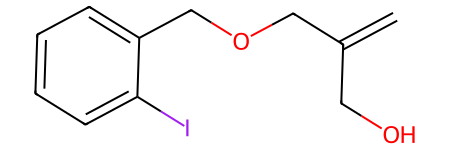

In [18]:
Chem.MolFromSmiles("IC1=CC=CC=C1COCC(CO)=C")

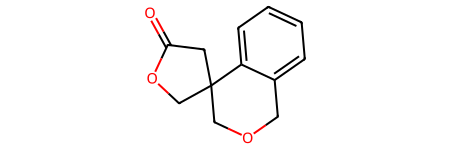

In [19]:
Chem.MolFromSmiles("O=C(OC2)CC32COCC4=CC=CC=C43")

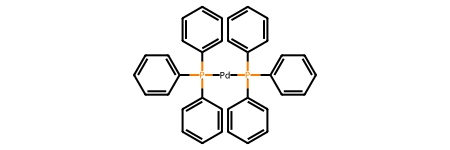

In [20]:
Chem.MolFromSmiles("[Pd]([P](c1ccccc1)(c2ccccc2)(c6ccccc6))([P](c3ccccc3)(c4ccccc4)(c5ccccc5))")

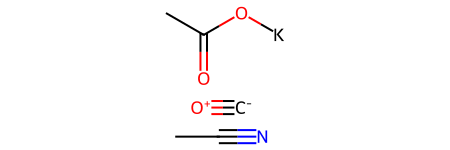

In [21]:
Chem.MolFromSmiles("CC#N.[C-]#[O+].[K]OC(=O)C")

In [22]:
x = "Br[Pd]C1(CC)CCCC1.CC2([Pd]Br)C=COC2.Br[Pd]C3(C(C)C)C=COC3.CC4([Pd]Br)CCCC4.Br[Pd]C5(C(C)C)CCCC5.Br[Pd]C1(C[H])C=COC1[H]"

In [23]:
x = x.split(".")

In [24]:
x = ["N(CC)(CC)CC.C1CCOC1." + i + ">>C" for i in x]

In [25]:
print(x)


['N(CC)(CC)CC.C1CCOC1.Br[Pd]C1(CC)CCCC1>>C', 'N(CC)(CC)CC.C1CCOC1.CC2([Pd]Br)C=COC2>>C', 'N(CC)(CC)CC.C1CCOC1.Br[Pd]C3(C(C)C)C=COC3>>C', 'N(CC)(CC)CC.C1CCOC1.CC4([Pd]Br)CCCC4>>C', 'N(CC)(CC)CC.C1CCOC1.Br[Pd]C5(C(C)C)CCCC5>>C', 'N(CC)(CC)CC.C1CCOC1.Br[Pd]C1(C[H])C=COC1[H]>>C']


In [26]:
for i in x:
    print(i)

N(CC)(CC)CC.C1CCOC1.Br[Pd]C1(CC)CCCC1>>C
N(CC)(CC)CC.C1CCOC1.CC2([Pd]Br)C=COC2>>C
N(CC)(CC)CC.C1CCOC1.Br[Pd]C3(C(C)C)C=COC3>>C
N(CC)(CC)CC.C1CCOC1.CC4([Pd]Br)CCCC4>>C
N(CC)(CC)CC.C1CCOC1.Br[Pd]C5(C(C)C)CCCC5>>C
N(CC)(CC)CC.C1CCOC1.Br[Pd]C1(C[H])C=COC1[H]>>C


In [27]:
# Read the file
input_file = "../data/p_heck.txt"
output_file = "../data/p_heck_mod.txt"

with open(input_file, "r", encoding="utf-8") as f:
    lines = f.readlines()

processed_lines = []
for line in lines:
    line = line.strip()
    if not line:
        continue  # skip empty lines

    # Step 1: split at first space
    parts = line.split(" ", 1)
    if len(parts) < 2:
        continue  # skip malformed lines
    part0, part1 = parts

    # Step 2: split part0 by '>>'
    subparts = part0.split(">>")
    if len(subparts) < 2:
        continue  # skip malformed lines

    # Step 3: duplicate element[1] with '.'
    subparts[1] = f"{subparts[1]}.{subparts[1]}"

    # Step 4: rebuild part0
    new_part0 = ">>".join(subparts)

    # Step 5: rejoin with the rest of the line
    processed_lines.append(f"{new_part0} {part1}")

# Write to new file
with open(output_file, "w", encoding="utf-8") as f:
    f.write("\n".join(processed_lines))

print(f"Processing complete. Saved to {output_file}")

Processing complete. Saved to ../data/p_heck_mod.txt


In [28]:
def draw_rxn (smi):
    smi1 = remove_atom_mapping(smi) #
    rxn = rdChemReactions.ReactionFromSmarts(smi1, useSmiles=True)
    return Draw.ReactionToImage(rxn, subImgSize=(800, 800))

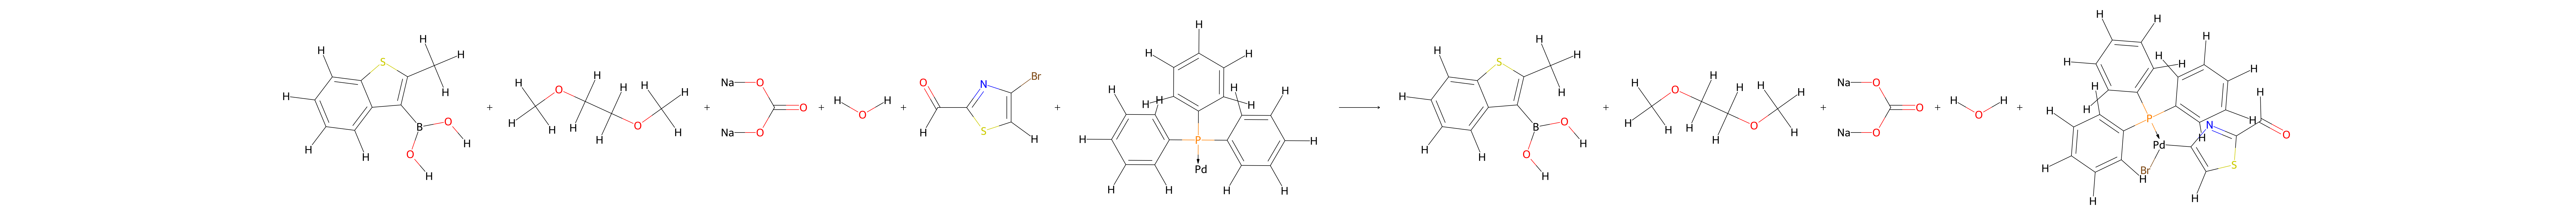

In [29]:
draw_rxn("[B:1]([c:2]1[c:3]([C:11]([H:59])([H:60])[H:61])[s:4][c:5]2[c:6]([H:55])[c:7]([H:56])[c:8]([H:57])[c:9]([H:58])[c:10]12)([O:12][H:62])[O:13][H:63].[C:22]([O:23][C:24]([C:25]([O:26][C:27]([H:73])([H:74])[H:75])([H:71])[H:72])([H:69])[H:70])([H:66])([H:67])[H:68].[C:47](=[O:48])([O:49][Na:50])[O:51][Na:52].[O:53]([H:91])[H:92].[c:14]1([H:64])[c:15]([Br:21])[n:16][c:17]([C:19](=[O:20])[H:65])[s:18]1.[c:28]1([H:76])[c:29]([H:77])[c:30]([H:78])[c:31]([P:34]([c:35]2[c:36]([H:81])[c:37]([H:82])[c:38]([H:83])[c:39]([H:84])[c:40]2[H:85])([c:41]2[c:42]([H:86])[c:43]([H:87])[c:44]([H:88])[c:45]([H:89])[c:46]2[H:90])->[Pd:54])[c:32]([H:79])[c:33]1[H:80]>>[B:1]([c:2]1[c:3]([C:11]([H:59])([H:60])[H:61])[s:4][c:5]2[c:6]([H:55])[c:7]([H:56])[c:8]([H:57])[c:9]([H:58])[c:10]12)([O:12][H:62])[O:13][H:63].[C:22]([O:23][C:24]([C:25]([O:26][C:27]([H:73])([H:74])[H:75])([H:71])[H:72])([H:69])[H:70])([H:66])([H:67])[H:68].[C:47](=[O:48])([O:49][Na:50])[O:51][Na:52].[O:53]([H:91])[H:92].[c:14]1([H:64])[c:15]([Pd:54]([Br:21])<-[P:34]([c:31]2[c:30]([H:78])[c:29]([H:77])[c:28]([H:76])[c:33]([H:80])[c:32]2[H:79])([c:35]2[c:36]([H:81])[c:37]([H:82])[c:38]([H:83])[c:39]([H:84])[c:40]2[H:85])[c:41]2[c:42]([H:86])[c:43]([H:87])[c:44]([H:88])[c:45]([H:89])[c:46]2[H:90])[n:16][c:17]([C:19](=[O:20])[H:65])[s:18]1")

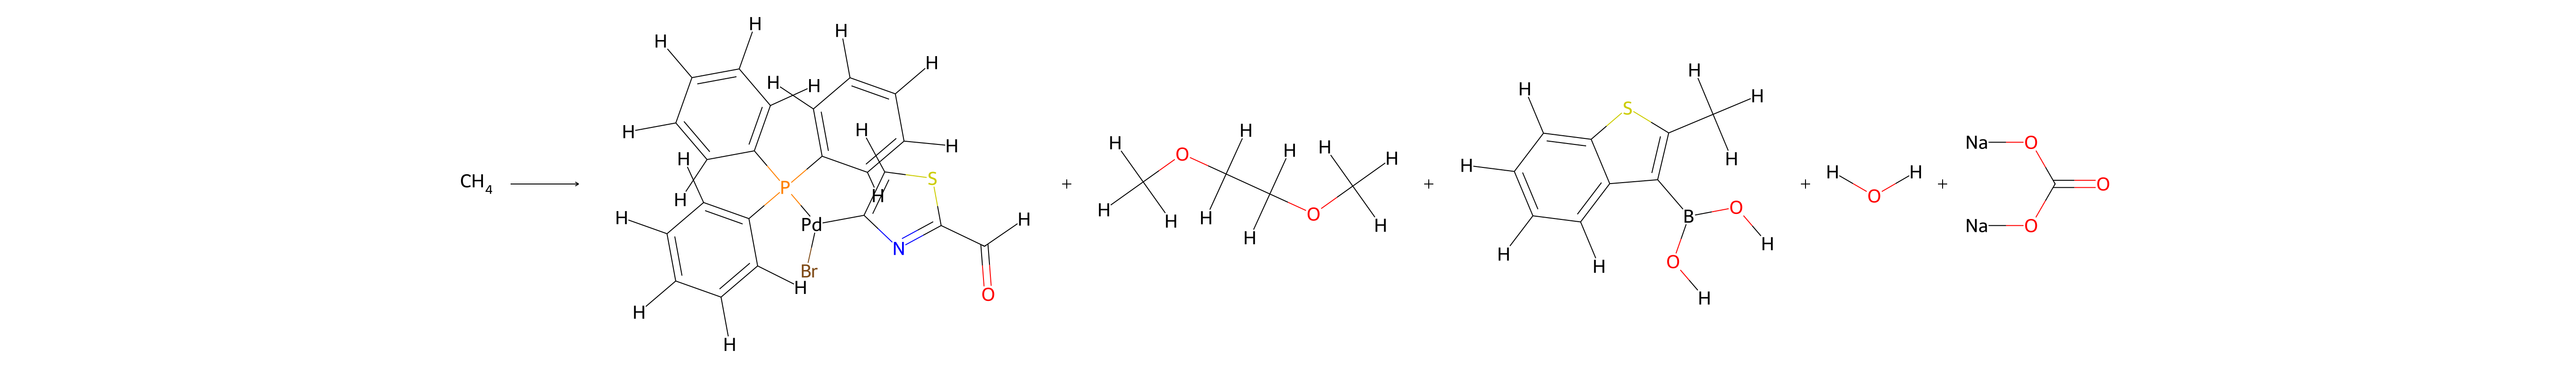

In [30]:
draw_rxn("C>>[H][C](=[O])[c]1[n][c]([Pd]([Br])[P]([c]2[c]([H])[c]([H])[c]([H])[c]([H])[c]2[H])([c]2[c]([H])[c]([H])[c]([H])[c]([H])[c]2[H])[c]2[c]([H])[c]([H])[c]([H])[c]([H])[c]2[H])[c]([H])[s]1.[H][C]([H])([H])[O][C]([H])([H])[C]([H])([H])[O][C]([H])([H])[H].[H][O][B]([O][H])[c]1[c]([C]([H])([H])[H])[s][c]2[c]([H])[c]([H])[c]([H])[c]([H])[c]12.[H][O][H].[O]=[C]([O][Na])[O][Na]")



In [31]:
draw_rxn("[B:1]1([B:10]2[O:11][C:12]([C:17]([H:118])([H:119])[H:120])([C:18]([H:121])([H:122])[H:123])[C:13]([C:15]([H:112])([H:113])[H:114])([C:16]([H:115])([H:116])[H:117])[O:14]2)[O:2][C:3]([C:8]([H:106])([H:107])[H:108])([C:9]([H:109])([H:110])[H:111])[C:4]([C:6]([H:100])([H:101])[H:102])([C:7]([H:103])([H:104])[H:105])[O:5]1.[C:46]([c:47]1[c:48]([H:141])[c:49]([H:142])[c:50]([H:143])[c:51]([H:144])[c:52]1[H:145])([H:138])([H:139])[H:140].[C:53]([C:54](=[O:55])[O:56][K:57])([H:146])([H:147])[H:148].[Cl:97][Pd:98][Cl:99].[H:177][C:178]([H:179])([H:180])[C:181](=[O:182])[O:183][K:184].[H:185][C:186]([H:187])([H:188])[C:189](=[O:190])[O:191][K:192].[N:95]#[N:96].[c:19]1([H:124])[c:20]([H:125])[c:21]2[c:22]([c:23]([H:126])[c:24]1[H:127])[n:25](-[c:32]1[c:33]([H:132])[c:34]3[c:35]([c:36]([H:133])[c:37]1[H:134])[o:38][c:39]1[c:40]3[c:41]([Br:45])[c:42]([H:135])[c:43]([H:136])[c:44]1[H:137])[c:26]1[c:27]2[c:28]([H:128])[c:29]([H:129])[c:30]([H:130])[c:31]1[H:131].[c:58]1([H:149])[c:59]([H:150])[c:60]([H:151])[c:61]([P:64]([c:65]2[c:66]([H:154])[c:67]([H:155])[c:68]([H:156])[c:69]([H:157])[c:70]2[H:158])[C:71]2([Fe:76][C:77]3([P:82]([c:83]4[c:84]([H:167])[c:85]([H:168])[c:86]([H:169])[c:87]([H:170])[c:88]4[H:171])[c:89]4[c:90]([H:172])[c:91]([H:173])[c:92]([H:174])[c:93]([H:175])[c:94]4[H:176])[C:78]([H:163])=[C:79]([H:164])[C:80]([H:165])=[C:81]3[H:166])[C:72]([H:159])=[C:73]([H:160])[C:74]([H:161])=[C:75]2[H:162])[c:62]([H:152])[c:63]1[H:153]>>[B:1]1([B:10]2[O:11][C:12]([C:17]([H:118])([H:119])[H:120])([C:18]([H:121])([H:122])[H:123])[C:13]([C:15]([H:112])([H:113])[H:114])([C:16]([H:115])([H:116])[H:117])[O:14]2)[O:2][C:3]([C:8]([H:106])([H:107])[H:108])([C:9]([H:109])([H:110])[H:111])[C:4]([C:6]([H:100])([H:101])[H:102])([C:7]([H:103])([H:104])[H:105])[O:5]1.[C:46]([c:47]1[c:48]([H:141])[c:49]([H:142])[c:50]([H:143])[c:51]([H:144])[c:52]1[H:145])([H:138])([H:139])[H:140].[C:53]([C:54](=[O:55])[O:56][K:57])([H:146])([H:147])[H:148].[H:177][C:178]([H:179])([H:180])[C:181](=[O:182])[O:183][K:184].[H:185][C:186]([H:187])([H:188])[C:189](=[O:190])[O:191][K:192].[N:95]#[N:96].[c:19]1([H:124])[c:20]([H:125])[c:21]2[c:22]([c:23]([H:126])[c:24]1[H:127])[n:25](-[c:32]1[c:33]([H:132])[c:34]3[c:35]([c:36]([H:133])[c:37]1[H:134])[o:38][c:39]1[c:40]3[c:41]([Br:45])[c:42]([H:135])[c:43]([H:136])[c:44]1[H:137])[c:26]1[c:27]2[c:28]([H:128])[c:29]([H:129])[c:30]([H:130])[c:31]1[H:131].[c:58]1([H:149])[c:59]([H:150])[c:60]([H:151])[c:61]([P:64]([c:65]2[c:66]([H:154])[c:67]([H:155])[c:68]([H:156])[c:69]([H:157])[c:70]2[H:158])([C:71]2([Fe:76][C:77]3([P:82]([c:83]4[c:84]([H:167])[c:85]([H:168])[c:86]([H:169])[c:87]([H:170])[c:88]4[H:171])[c:89]4[c:90]([H:172])[c:91]([H:173])[c:92]([H:174])[c:93]([H:175])[c:94]4[H:176])[C:78]([H:163])=[C:79]([H:164])[C:80]([H:165])=[C:81]3[H:166])[C:72]([H:159])=[C:73]([H:160])[C:74]([H:161])=[C:75]2[H:162])->[Pd:98]([Cl:97])[Cl:99])[c:62]([H:152])[c:63]1[H:153]")

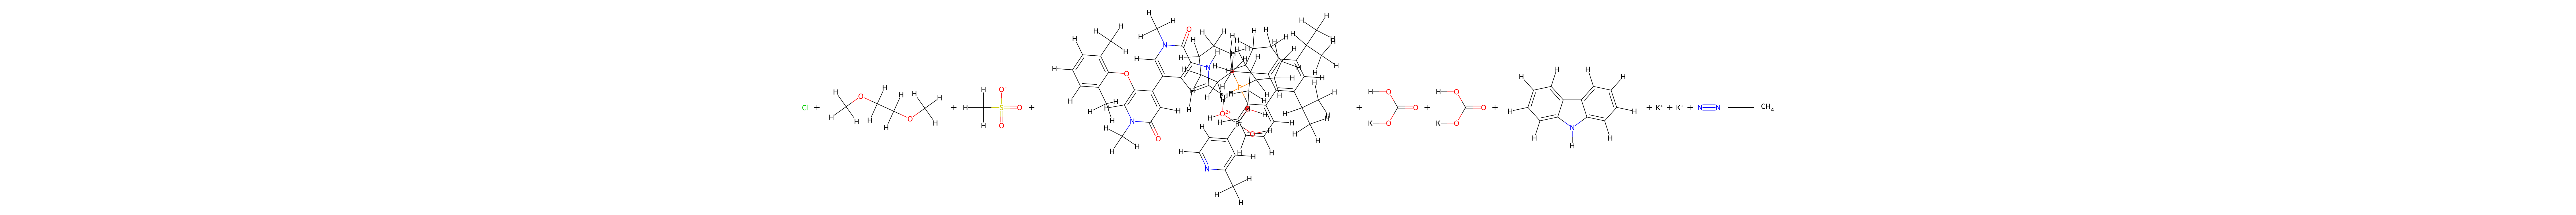

In [32]:
draw_rxn("[Cl-].[H][C]([H])([H])[O][C]([H])([H])[C]([H])([H])[O][C]([H])([H])[H].[H][C]([H])([H])[S](=[O])(=[O])[O-].[H][O][B-]([O][H])([c]1[c]([H])[c]([H])[n][c]([C]([H])([H])[H])[c]1[H])[O+2]([H])[Pd-]([c]1[c]([H])[c]2[c](-[c]3[c]([O][c]4[c]([C]([H])([H])[H])[c]([H])[c]([H])[c]([H])[c]4[C]([H])([H])[H])[c]([H])[n]([C]([H])([H])[H])[c](=[O])[c]3[H])[c]([H])[n]([C]([H])([H])[H])[c](=[O])[c]2[n]1[H])<-[P]([c]1[c]([H])[c]([H])[c]([H])[c]([H])[c]1-[c]1[c]([C]([H])([C]([H])([H])[H])[C]([H])([H])[H])[c]([H])[c]([C]([H])([C]([H])([H])[H])[C]([H])([H])[H])[c]([H])[c]1[C]([H])([C]([H])([H])[H])[C]([H])([H])[H])([C]1([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]1([H])[H])[C]1([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]1([H])[H].[H][O][C](=[O])[O][K].[H][O][C](=[O])[O][K].[H][c]1[c]([H])[c]([H])[c]2[c]([c]1[H])[c]1[c]([H])[c]([H])[c]([H])[c]([H])[c]1[n]2[H].[K+].[K+].[N]#[N]>>C")

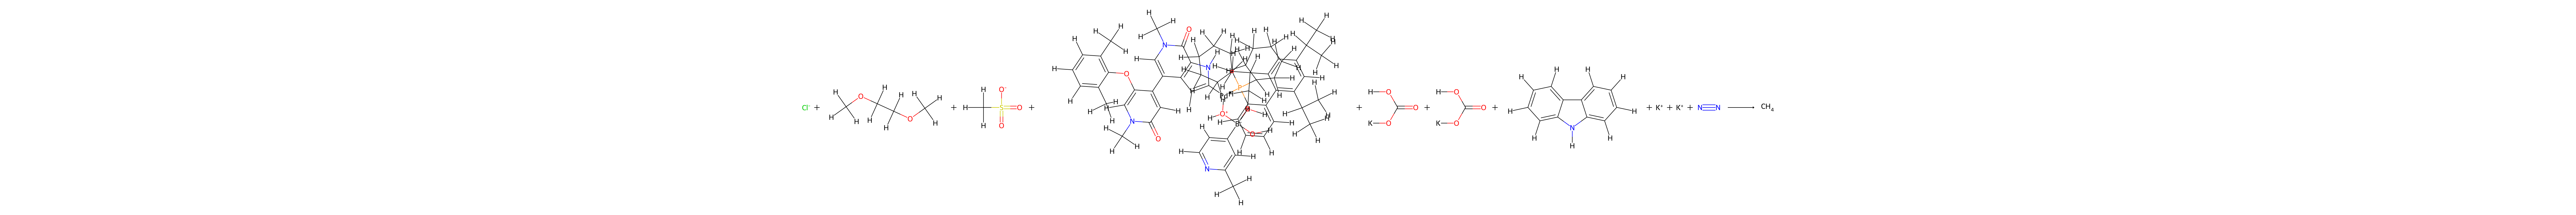

In [33]:
draw_rxn("[Cl-].[H][C]([H])([H])[O][C]([H])([H])[C]([H])([H])[O][C]([H])([H])[H].[H][C]([H])([H])[S](=[O])(=[O])[O-].[H][O][B-]([O][H])([c]1[c]([H])[c]([H])[n][c]([C]([H])([H])[H])[c]1[H])[O+]([H])[Pd]([c]1[c]([H])[c]2[c](-[c]3[c]([O][c]4[c]([C]([H])([H])[H])[c]([H])[c]([H])[c]([H])[c]4[C]([H])([H])[H])[c]([H])[n]([C]([H])([H])[H])[c](=[O])[c]3[H])[c]([H])[n]([C]([H])([H])[H])[c](=[O])[c]2[n]1[H])<-[P]([c]1[c]([H])[c]([H])[c]([H])[c]([H])[c]1-[c]1[c]([C]([H])([C]([H])([H])[H])[C]([H])([H])[H])[c]([H])[c]([C]([H])([C]([H])([H])[H])[C]([H])([H])[H])[c]([H])[c]1[C]([H])([C]([H])([H])[H])[C]([H])([H])[H])([C]1([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]1([H])[H])[C]1([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]([H])([H])[C]1([H])[H].[H][O][C](=[O])[O][K].[H][O][C](=[O])[O][K].[H][c]1[c]([H])[c]([H])[c]2[c]([c]1[H])[c]1[c]([H])[c]([H])[c]([H])[c]([H])[c]1[n]2[H].[K+].[K+].[N]#[N]>>C")

draw_rxn("[C:1]([C:2]([C:3]([H:112])([H:113])[H:114])([c:4]1[c:5]([H:115])[c:6]([C:7]([C:8]([H:117])([H:118])[H:119])([C:9]([H:120])([H:121])[H:122])[H:116])[c:10](-[c:11]2[c:12]([H:123])[c:13]([H:124])[c:14]([H:125])[c:15]([H:126])[c:16]2[P:17]([C:18]2([H:127])[C:19]([H:128])([H:129])[C:20]([H:130])([H:131])[C:21]([H:132])([H:133])[C:22]([H:134])([H:135])[C:23]2([H:136])[H:137])([C:24]2([H:138])[C:25]([H:139])([H:140])[C:26]([H:141])([H:142])[C:27]([H:143])([H:144])[C:28]([H:145])([H:146])[C:29]2([H:147])[H:148])->[Pd:30]([c:65]2[c:66]([H:178])[c:67]3[c:68](-[c:69]4[c:70]([O:71][c:72]5[c:73]([C:74]([H:179])([H:180])[H:181])[c:75]([H:182])[c:76]([H:183])[c:77]([H:184])[c:78]5[C:79]([H:185])([H:186])[H:187])[c:80]([H:188])[n:81]([C:82]([H:189])([H:190])[H:191])[c:83](=[O:84])[c:85]4[H:192])[c:86]([H:193])[n:87]([C:88]([H:194])([H:195])[H:196])[c:89](=[O:90])[c:91]3[n:92]2[H:197])[O:107][H:208])[c:49]([C:50]([C:51]([H:163])([H:164])[H:165])([C:52]([H:166])([H:167])[H:168])[H:162])[c:53]1[H:169])[H:111])([H:108])([H:109])[H:110].[C:93]([O:94][C:95]([C:96]([O:97][C:98]([H:205])([H:206])[H:207])([H:203])[H:204])([H:201])[H:202])([H:198])([H:199])[H:200].[Cl-:64].[H:209][O:212][C:211](=[O:210])[O:214][K:215].[K+:102].[K+:213].[N:105]#[N:106].[O-:31][S:32]([C:33]([H:149])([H:150])[H:151])(=[O:34])=[O:35].[O:54]([B:55]([O:56][H:171])[c:57]1[c:58]([H:172])[c:59]([C:60]([H:173])([H:174])[H:175])[n:61][c:62]([H:176])[c:63]1[H:177])[H:170].[O:99]=[C:100]([O:101][H:161])[O:103][K:104].[c:36]12[c:37]([H:152])[c:38]([H:153])[c:39]([H:154])[c:40]([H:155])[c:41]1[c:42]1[c:43]([H:156])[c:44]([H:157])[c:45]([H:158])[c:46]([H:159])[c:47]1[n:48]2[H:160]>>[C:1]([C:2]([C:3]([H:112])([H:113])[H:114])([c:4]1[c:5]([H:115])[c:6]([C:7]([C:8]([H:117])([H:118])[H:119])([C:9]([H:120])([H:121])[H:122])[H:116])[c:10](-[c:11]2[c:12]([H:123])[c:13]([H:124])[c:14]([H:125])[c:15]([H:126])[c:16]2[P:17]([C:18]2([H:127])[C:19]([H:128])([H:129])[C:20]([H:130])([H:131])[C:21]([H:132])([H:133])[C:22]([H:134])([H:135])[C:23]2([H:136])[H:137])([C:24]2([H:138])[C:25]([H:139])([H:140])[C:26]([H:141])([H:142])[C:27]([H:143])([H:144])[C:28]([H:145])([H:146])[C:29]2([H:147])[H:148])->[Pd:30]([c:65]2[c:66]([H:178])[c:67]3[c:68](-[c:69]4[c:70]([O:71][c:72]5[c:73]([C:74]([H:179])([H:180])[H:181])[c:75]([H:182])[c:76]([H:183])[c:77]([H:184])[c:78]5[C:79]([H:185])([H:186])[H:187])[c:80]([H:188])[n:81]([C:82]([H:189])([H:190])[H:191])[c:83](=[O:84])[c:85]4[H:192])[c:86]([H:193])[n:87]([C:88]([H:194])([H:195])[H:196])[c:89](=[O:90])[c:91]3[n:92]2[H:197])[O+:107]([B-:55]([O:54][H:170])([O:56][H:171])[c:57]2[c:58]([H:172])[c:59]([C:60]([H:173])([H:174])[H:175])[n:61][c:62]([H:176])[c:63]2[H:177])[H:208])[c:49]([C:50]([C:51]([H:163])([H:164])[H:165])([C:52]([H:166])([H:167])[H:168])[H:162])[c:53]1[H:169])[H:111])([H:108])([H:109])[H:110].[C:93]([O:94][C:95]([C:96]([O:97][C:98]([H:205])([H:206])[H:207])([H:203])[H:204])([H:201])[H:202])([H:198])([H:199])[H:200].[Cl-:64].[H:209][O:212][C:211](=[O:210])[O:214][K:215].[K+:102].[K+:213].[N:105]#[N:106].[O-:31][S:32]([C:33]([H:149])([H:150])[H:151])(=[O:34])=[O:35].[O:99]=[C:100]([O:101][H:161])[O:103][K:104].[c:36]12[c:37]([H:152])[c:38]([H:153])[c:39]([H:154])[c:40]([H:155])[c:41]1[c:42]1[c:43]([H:156])[c:44]([H:157])[c:45]([H:158])[c:46]([H:159])[c:47]1[n:48]2[H:160]")



In [34]:
draw_rxn("[B:1]1([C:10](=[C:11]([C:12]([C:13]([H:125])([H:126])[H:127])([N:14]2[C:15](=[O:24])[c:16]3[c:17]([c:20]([H:128])[c:21]([H:129])[c:22]([H:130])[c:23]3[H:131])[C:18]2=[O:19])[H:124])[H:123])[H:122])[O:2][C:3]([C:8]([H:116])([H:117])[H:118])([C:9]([H:119])([H:120])[H:121])[C:4]([C:6]([H:110])([H:111])[H:112])([C:7]([H:113])([H:114])[H:115])[O:5]1.[C:102](=[O:103])([O:104][Na:105])[O:106][Na:107].[C:25]([C:26]([O:27][c:28]1[c:29]([H:137])[c:30]([H:138])[c:31]([O:35][c:36]2[n:37][c:38]([H:140])[c:39]([Br:42])[c:40]([H:141])[c:41]2[H:142])[c:32]([Cl:34])[c:33]1[H:139])([H:135])[H:136])([H:132])([H:133])[H:134].[C:43]([C:44]([N:45]=[C:46]=[N+:47]([C:48]([C:49]([C:50]([N:51]([C:52]([H:154])([H:155])[H:156])[C:53]([H:157])([H:158])[H:159])([H:152])[H:153])([H:150])[H:151])([H:148])[H:149])[H:198])([H:146])[H:147])([H:143])([H:144])[H:145].[C:54]([C:55]([O:56][H:165])([H:163])[H:164])([H:160])([H:161])[H:162].[C:98]([Cl:99])([Cl:100])([Cl:101])[H:196].[Cl-:96].[Cl:109][H:199].[H:200][O:201][H:202].[H:203][C:204]([H:205])([H:206])[C:207]([H:208])([H:209])[N:210]=[C:211]=[N:212][C:213]([H:214])([H:215])[C:216]([H:217])([H:218])[C:219]([H:220])([H:221])[N:222]([C:223]([H:224])([H:225])[H:226])[C:227]([H:228])([H:229])[H:230].[c:57]1([H:166])[c:58]([H:167])[c:59]([H:168])[c:60]([P:63]([c:64]2[c:65]([H:171])[c:66]([H:172])[c:67]([H:173])[c:68]([H:174])[c:69]2[H:175])([c:70]2[c:71]([H:176])[c:72]([H:177])[c:73]([H:178])[c:74]([H:179])[c:75]2[H:180])->[Pd:76](<-[P:77]([c:78]2[c:79]([H:181])[c:80]([H:182])[c:81]([H:183])[c:82]([H:184])[c:83]2[H:185])([c:84]2[c:85]([H:186])[c:86]([H:187])[c:87]([H:188])[c:88]([H:189])[c:89]2[H:190])[c:90]2[c:91]([H:191])[c:92]([H:192])[c:93]([H:193])[c:94]([H:194])[c:95]2[H:195])([Cl:97])[O:108][H:197])[c:61]([H:169])[c:62]1[H:170]>>[B:1]1([C:10](=[C:11]([C:12]([C:13]([H:125])([H:126])[H:127])([N:14]2[C:15](=[O:24])[c:16]3[c:17]([c:20]([H:128])[c:21]([H:129])[c:22]([H:130])[c:23]3[H:131])[C:18]2=[O:19])[H:124])[H:123])[H:122])[O:2][C:3]([C:8]([H:116])([H:117])[H:118])([C:9]([H:119])([H:120])[H:121])[C:4]([C:6]([H:110])([H:111])[H:112])([C:7]([H:113])([H:114])[H:115])[O:5]1.[C:102](=[O:103])([O:104][Na:105])[O:106][Na:107].[C:25]([C:26]([O:27][c:28]1[c:29]([H:137])[c:30]([H:138])[c:31]([O:35][c:36]2[n:37][c:38]([H:140])[c:39]([Br:42])[c:40]([H:141])[c:41]2[H:142])[c:32]([Cl:34])[c:33]1[H:139])([H:135])[H:136])([H:132])([H:133])[H:134].[C:43]([C:44]([N:45]=[C:46]=[N+:47]([C:48]([C:49]([C:50]([N:51]([C:52]([H:154])([H:155])[H:156])[C:53]([H:157])([H:158])[H:159])([H:152])[H:153])([H:150])[H:151])([H:148])[H:149])[H:198])([H:146])[H:147])([H:143])([H:144])[H:145].[C:54]([C:55]([O:56][H:165])([H:163])[H:164])([H:160])([H:161])[H:162].[C:98]([Cl:99])([Cl:100])([Cl:101])[H:196].[Cl-:96].[Cl:109][H:199].[Pd-:76](<-[P:77]([c:78]1[c:79]([H:181])[c:80]([H:182])[c:81]([H:183])[c:82]([H:184])[c:83]1[H:185])([c:84]1[c:85]([H:186])[c:86]([H:187])[c:87]([H:188])[c:88]([H:189])[c:89]1[H:190])[c:90]1[c:91]([H:191])[c:92]([H:192])[c:93]([H:193])[c:94]([H:194])[c:95]1[H:195])[Cl:97].[c:57]1([H:166])[c:58]([H:167])[c:59]([H:168])[c:60]([P+:63]([c:64]2[c:65]([H:171])[c:66]([H:172])[c:67]([H:173])[c:68]([H:174])[c:69]2[H:175])([c:70]2[c:71]([H:176])[c:72]([H:177])[c:73]([H:178])[c:74]([H:179])[c:75]2[H:180])[O:108][H:197])[c:61]([H:169])[c:62]1[H:170]")

draw_rxn("[Br:64][c:65]1[c:66]2[c:67]([c:68]3[c:69]([c:70]1[Cl:71])[O:72][C:73]([H:170])([H:171])[C:74]1([H:172])[N:75]([C:76]([H:173])([H:174])[C:77]([H:175])([H:176])[N:78]([C:79]([O:80][C:81]([C:82]([H:177])([H:178])[H:179])([C:83]([H:180])([H:181])[H:182])[C:84]([H:183])([H:184])[H:185])=[O:85])[C:86]1([H:186])[H:187])[C:87]3=[O:88])[n:89]([C:90]([H:188])([H:189])[H:190])[c:91]([H:191])[n:92]2.[C:1]([C:2]([C:3]([H:112])([H:113])[H:114])([O:4][c:5]1[c:6]([H:115])[c:7]([H:116])[c:8]([H:117])[c:9]([O:10][C:11]([C:12]([H:119])([H:120])[H:121])([C:13]([H:122])([H:123])[H:124])[H:118])[c:14]1-[c:15]1[c:16]([H:125])[c:17]([H:126])[c:18]([H:127])[c:19]([H:128])[c:20]1[P:21]([C:22]1([H:129])[C:23]([H:130])([H:131])[C:24]([H:132])([H:133])[C:25]([H:134])([H:135])[C:26]([H:136])([H:137])[C:27]1([H:138])[H:139])([C:28]1([H:140])[C:29]([H:141])([H:142])[C:30]([H:143])([H:144])[C:31]([H:145])([H:146])[C:32]([H:147])([H:148])[C:33]1([H:149])[H:150])->[Pd:34]([O:35][S:36]([C:37]([H:151])([H:152])[H:153])(=[O:38])=[O:39])[c:40]1[c:41]([H:154])[c:42]([H:155])[c:43]([H:156])[c:44]([H:157])[c:45]1-[c:46]1[c:47]([H:158])[c:48]([H:159])[c:49]([H:160])[c:50]([H:161])[c:51]1[N:52]([H:162])[H:163])[H:111])([H:108])([H:109])[H:110].[C:93]1([H:192])([H:193])[C:94]([H:194])([H:195])[O:95][C:96]([H:196])([H:197])[C:97]([H:198])([H:199])[O:98]1.[H:201][O:204][C:203](=[O:202])[O:206][K:207].[K+:205].[N:105]#[N:106].[O:107]([H:200])[H:201].[O:53]([B:54]([O:55][H:165])[c:56]1[c:57]([Cl:58])[c:59]([H:166])[c:60]([H:167])[c:61]([H:168])[c:62]1[O:63][H:169])[H:164].[O:99]=[C:100]([O:101][K:102])[O:103][K:104]>>[Br:64][c:65]1[c:66]2[c:67]([c:68]3[c:69]([c:70]1[Cl:71])[O:72][C:73]([H:170])([H:171])[C:74]1([H:172])[N:75]([C:76]([H:173])([H:174])[C:77]([H:175])([H:176])[N:78]([C:79]([O:80][C:81]([C:82]([H:177])([H:178])[H:179])([C:83]([H:180])([H:181])[H:182])[C:84]([H:183])([H:184])[H:185])=[O:85])[C:86]1([H:186])[H:187])[C:87]3=[O:88])[n:89]([C:90]([H:188])([H:189])[H:190])[c:91]([H:191])[n:92]2.[C:1]([C:2]([C:3]([H:112])([H:113])[H:114])([O:4][c:5]1[c:6]([H:115])[c:7]([H:116])[c:8]([H:117])[c:9]([O:10][C:11]([C:12]([H:119])([H:120])[H:121])([C:13]([H:122])([H:123])[H:124])[H:118])[c:14]1-[c:15]1[c:16]([H:125])[c:17]([H:126])[c:18]([H:127])[c:19]([H:128])[c:20]1[P:21]([C:22]1([H:129])[C:23]([H:130])([H:131])[C:24]([H:132])([H:133])[C:25]([H:134])([H:135])[C:26]([H:136])([H:137])[C:27]1([H:138])[H:139])([C:28]1([H:140])[C:29]([H:141])([H:142])[C:30]([H:143])([H:144])[C:31]([H:145])([H:146])[C:32]([H:147])([H:148])[C:33]1([H:149])[H:150])->[Pd:34]1[c:40]2[c:41]([H:154])[c:42]([H:155])[c:43]([H:156])[c:44]([H:157])[c:45]2-[c:46]2[c:47]([H:158])[c:48]([H:159])[c:49]([H:160])[c:50]([H:161])[c:51]2[N:52]1[H:162])[H:111])([H:108])([H:109])[H:110].[C:93]1([H:192])([H:193])[C:94]([H:194])([H:195])[O:95][C:96]([H:196])([H:197])[C:97]([H:198])([H:199])[O:98]1.[H:201][O:204][C:203](=[O:202])[O:206][K:207].[K+:102].[K+:205].[N:105]#[N:106].[O-:35][S:36]([C:37]([H:151])([H:152])[H:153])(=[O:38])=[O:39].[O:107]([H:200])[H:201].[O:53]([B:54]([O:55][H:165])[c:56]1[c:57]([Cl:58])[c:59]([H:166])[c:60]([H:167])[c:61]([H:168])[c:62]1[O:63][H:169])[H:164].[O:99]=[C:100]([O:101][H:163])[O:103][K:104]")

In [35]:
smi_test = "[C:1]([C:2]([C:3]([H:112])([H:113])[H:114])([O:4][c:5]1[c:6]([H:115])[c:7]([H:116])[c:8]([H:117])[c:9]([O:10][C:11]([C:12]([H:119])([H:120])[H:121])([C:13]([H:122])([H:123])[H:124])[H:118])[c:14]1-[c:15]1[c:16]([H:125])[c:17]([H:126])[c:18]([H:127])[c:19]([H:128])[c:20]1[P:21]([C:22]1([H:129])[C:23]([H:130])([H:131])[C:24]([H:132])([H:133])[C:25]([H:134])([H:135])[C:26]([H:136])([H:137])[C:27]1([H:138])[H:139])([C:28]1([H:140])[C:29]([H:141])([H:142])[C:30]([H:143])([H:144])[C:31]([H:145])([H:146])[C:32]([H:147])([H:148])[C:33]1([H:149])[H:150])[Pd:34]([O:35][S:36]([C:37]([H:151])([H:152])[H:153])(=[O:38])=[O:39])[c:40]1[c:41]([H:154])[c:42]([H:155])[c:43]([H:156])[c:44]([H:157])[c:45]1-[c:46]1[c:47]([H:158])[c:48]([H:159])[c:49]([H:160])[c:50]([H:161])[c:51]1[N:52]([H:162])[H:163])[H:111])([H:108])([H:109])[H:110]"

In [36]:
mol = Chem.MolFromSmiles(smi_test)
for atom in mol.GetAtoms():
    if atom.GetAtomicNum() == 46:
        print([n.GetAtomicNum() for n in atom.GetNeighbors()])

[15, 8, 6]


In [37]:
batch_size = 5

def show_random_batch(b=None):
    clear_output(wait=True)
    # sample 5 random indices without replacement
    if len(untemplated_df) < batch_size:
        sample_indices = list(range(len(untemplated_df)))
    else:
        sample_indices = random.sample(range(len(untemplated_df)), batch_size)
        
    smiles_list = untemplated_df['smiles'].iloc[sample_indices]
    max_len = 100  # adjust as needed
    for idx, s in smiles_list.items():
        s = str(s)
        print(f"{idx}: {s[:max_len]}{'...' if len(s) > max_len else ''}")
    
    rxns = []
    for s in smiles_list:
        try:
            rxn = rdChemReactions.ReactionFromSmarts(remove_atom_mapping(s), useSmiles=True)
            if rxn is not None:
                rxns.append(rxn)
        except Exception as e:
            print(f"Failed to parse: {s} ({e})")
    
    if rxns:
        images = []
        for rxn in rxns:
            img = Draw.ReactionToImage(rxn, subImgSize=(800, 300))
            if img.mode != "RGB":
                img = img.convert("RGB")
            images.append(img)
        if not images:
            print("No images to display.")
            return
        img_w, img_h = images[0].size
        per_row = 1
        rows = (len(images) + per_row - 1) // per_row
        grid_img = Image.new('RGB', (per_row * img_w, rows * img_h), (255, 255, 255))
        for idx, img in enumerate(images):
            x = (idx % per_row) * img_w
            y = (idx // per_row) * img_h
            grid_img.paste(img, (x, y))
        display(grid_img)
        display(next_button)
    else:
        print("No valid reactions found to display.")

next_button = widgets.Button(description="Next 5 Random")
next_button.on_click(show_random_batch)

# Show the first random batch and button
show_random_batch()

NameError: name 'clear_output' is not defined

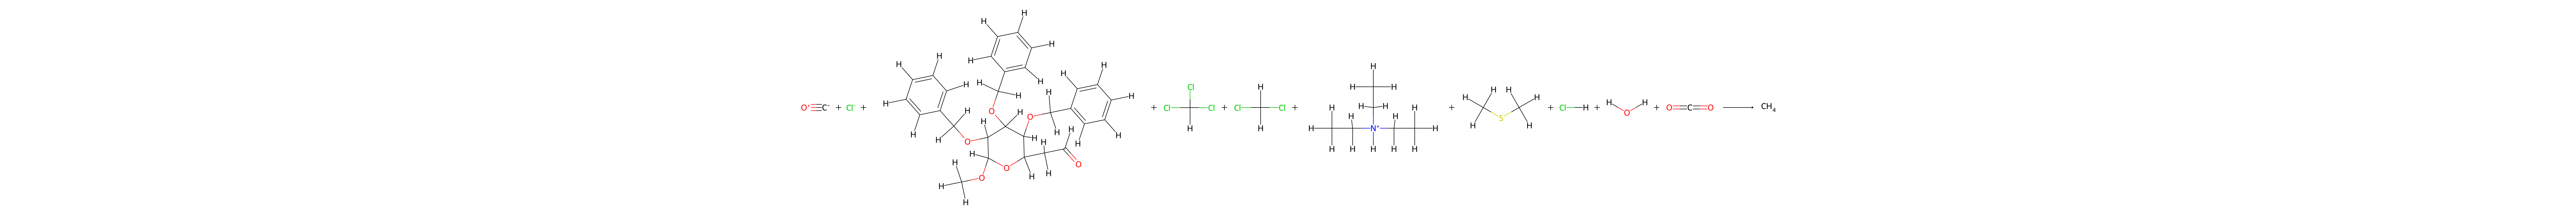

In [39]:
draw_rxn("[C-]#[O+].[Cl-].[H][C](=[O])[C]([H])([H])[C]1([H])[O][C]([H])([O][C]([H])([H])[H])[C]([H])([O][C]([H])([H])[c]2=[c]([H])-[c]([H])=[c]([H])-[c]([H])=[c]-2[H])[C]([H])([O][C]([H])([H])[c]2=[c]([H])-[c]([H])=[c]([H])-[c]([H])=[c]-2[H])[C]1([H])[O][C]([H])([H])[c]1=[c]([H])-[c]([H])=[c]([H])-[c]([H])=[c]-1[H].[H][C]([Cl])([Cl])[Cl].[H][C]([H])([Cl])[Cl].[H][C]([H])([H])[C]([H])([H])[N+]([H])([C]([H])([H])[C]([H])([H])[H])[C]([H])([H])[C]([H])([H])[H].[H][C]([H])([H])[S][C]([H])([H])[H].[H][Cl].[H][O][H].[O]=[C]=[O]>>C")